In [ ]:
import os
import pandas as pd
import librosa
import re
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib_venn import venn3
from tqdm import tqdm
import cv2
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    f1_score,
    mutual_info_score, normalized_mutual_info_score
)
from sklearn.utils import resample
import shap
from collections import Counter
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
import joblib
from scipy.stats import entropy
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from collections import defaultdict

In [ ]:
prosodic = ['F0semitoneFrom27.5Hz_sma3nz_amean', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm',
            'F0semitoneFrom27.5Hz_sma3nz_percentile20.0', 'F0semitoneFrom27.5Hz_sma3nz_percentile50.0',
            'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2',
            'F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope', 'F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope',
            'F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope', 'F0semitoneFrom27.5Hz_sma3nz_stddevFallingSlope',
            'loudness_sma3_amean', 'loudness_sma3_stddevNorm', 'loudness_sma3_percentile20.0',
            'loudness_sma3_percentile50.0', 'loudness_sma3_percentile80.0', 'loudness_sma3_pctlrange0-2',
            'loudness_sma3_meanRisingSlope', 'loudness_sma3_stddevRisingSlope', 'loudness_sma3_meanFallingSlope',
            'loudness_sma3_stddevFallingSlope', 'loudnessPeaksPerSec', 'VoicedSegmentsPerSec',
            'MeanVoicedSegmentLengthSec', 'StddevVoicedSegmentLengthSec', 'MeanUnvoicedSegmentLength',
            'StddevUnvoicedSegmentLength', 'equivalentSoundLevel_dBp', 'delta_energy_mean',
            'delta_energy_std', 'delta_pitch_std', 'delta_pitch_mean', 'st_loudness_variability', 'lt_loudness_variability',
            'jitterLocal_sma3nz_amean', 'pitch_variability', 'melodic_deviation', 'dett_mean', 'dett_std', 'dett_cv', 'pitch_bias',
            'jitterLocal_sma3nz_stddevNorm', 'shimmerLocaldB_sma3nz_amean', 'shimmerLocaldB_sma3nz_stddevNorm']

spectral = ['spectralFlux_sma3_amean', 'spectralFlux_sma3_stddevNorm',
            'HNRdBACF_sma3nz_amean', 'HNRdBACF_sma3nz_stddevNorm', 'logRelF0-H1-H2_sma3nz_amean',
            'logRelF0-H1-H2_sma3nz_stddevNorm', 'logRelF0-H1-A3_sma3nz_amean', 'logRelF0-H1-A3_sma3nz_stddevNorm',
            'F1frequency_sma3nz_amean', 'F1frequency_sma3nz_stddevNorm', 'F1bandwidth_sma3nz_amean',
            'F1bandwidth_sma3nz_stddevNorm', 'F1amplitudeLogRelF0_sma3nz_amean', 'F1amplitudeLogRelF0_sma3nz_stddevNorm',
            'F2frequency_sma3nz_amean', 'F2frequency_sma3nz_stddevNorm', 'F2bandwidth_sma3nz_amean',
            'F2bandwidth_sma3nz_stddevNorm', 'F2amplitudeLogRelF0_sma3nz_amean', 'F2amplitudeLogRelF0_sma3nz_stddevNorm',
            'F3frequency_sma3nz_amean', 'F3frequency_sma3nz_stddevNorm', 'F3bandwidth_sma3nz_amean',
            'F3bandwidth_sma3nz_stddevNorm', 'F3amplitudeLogRelF0_sma3nz_amean', 'F3amplitudeLogRelF0_sma3nz_stddevNorm',
            'alphaRatioV_sma3nz_amean', 'alphaRatioV_sma3nz_stddevNorm', 'hammarbergIndexV_sma3nz_amean',
            'hammarbergIndexV_sma3nz_stddevNorm', 'slopeV0-500_sma3nz_amean', 'slopeV0-500_sma3nz_stddevNorm',
            'slopeV500-1500_sma3nz_amean', 'slopeV500-1500_sma3nz_stddevNorm', 'spectralFluxV_sma3nz_amean',
            'spectralFluxV_sma3nz_stddevNorm', 'alphaRatioUV_sma3nz_amean', 'hammarbergIndexUV_sma3nz_amean',
            'slopeUV0-500_sma3nz_amean', 'slopeUV500-1500_sma3nz_amean', 'spectralFluxUV_sma3nz_amean',
            'spectral_flatness_mean', 'spectral_flatness_std', 'spectral_centroid_mean', 'spectral_centroid_std', 'zcr_mean', 'zcr_std',
            ]

phonemes = ['phoneme_duration_cv',
            'articulation_rate',
            'vowel_ratio',
            #'consonant_ratio',
            'avg_distance_pauses',
            'mean_pause_duration',
            'std_pause_duration',
            'mean_phoneme_duration',
            'std_phoneme_duration',
            'pause_ratio']

techniques = ['vibrato_mean', 'vibrato_std', 'vibrato_max',
              'vibrato_peak_factor', 'mix_mean', 'mix_std', 'mix_max',
              'mix_peak_factor', 'falsetto_mean', 'falsetto_std', 'falsetto_max',
              'falsetto_peak_factor', 'breathy_mean', 'breathy_std', 'breathy_max',
              'breathy_peak_factor', 'pharyngeal_mean', 'pharyngeal_std',
              'pharyngeal_max', 'pharyngeal_peak_factor', 'glissando_mean',
              'glissando_std', 'glissando_max', 'glissando_peak_factor',
              'num_tech_changes', 'tech_entropy',  'MFDR_slow',
              'MFDR_vibrato', 'MFDR_high',
              'MFDR_slow2vibrato', 'MFDR_vibrato2high']

all_features = prosodic + spectral + phonemes + techniques
len(all_features)

130

# RAVDESS

In [ ]:
df_ravdess.columns.to_list()

['modality',
 'vocal_channel',
 'emotion',
 'intensity',
 'statement',
 'repetition',
 'actor_id',
 'gender',
 'F0semitoneFrom27.5Hz_sma3nz_amean',
 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm',
 'F0semitoneFrom27.5Hz_sma3nz_percentile20.0',
 'F0semitoneFrom27.5Hz_sma3nz_percentile50.0',
 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0',
 'F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2',
 'F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope',
 'F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope',
 'F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope',
 'F0semitoneFrom27.5Hz_sma3nz_stddevFallingSlope',
 'loudness_sma3_amean',
 'loudness_sma3_stddevNorm',
 'loudness_sma3_percentile20.0',
 'loudness_sma3_percentile50.0',
 'loudness_sma3_percentile80.0',
 'loudness_sma3_pctlrange0-2',
 'loudness_sma3_meanRisingSlope',
 'loudness_sma3_stddevRisingSlope',
 'loudness_sma3_meanFallingSlope',
 'loudness_sma3_stddevFallingSlope',
 'spectralFlux_sma3_amean',
 'spectralFlux_sma3_stddevNorm',
 'mfcc1_sma3_amean',
 'mfcc1_sma3_stdde

In [ ]:
df_ravdess = pd.read_csv('df_ravdess_check(3).csv')

In [ ]:
df_ravdess.shape

(1012, 157)

In [ ]:
df_ravdess.gender.value_counts()

,count
gender,
male,528
female,484


In [ ]:
df_ravdess.emotion.value_counts()

,count
emotion,
3,184
5,184
4,184
6,184
2,184
1,92


## Leave-One-Speaker Out Evaluation

In [ ]:
def loso_evaluation(df, feature_cols, model, target_col, group_col='actor_id', plot_cm=True):
    """
    Runs a Leave-One-Speaker-Out (LOSO) evaluation
    """

    emotion_labels = ['Neutral', 'Calm', 'Happy', 'Sad', 'Angry', 'Fearful']

    X = df[feature_cols].values
    y = df[target_col].values
    groups = df[group_col].values

    logo = LeaveOneGroupOut()

    balanced_accuracies = []
    y_true_all, y_pred_all = [], []
    macro_f1s = []

    print("Starting Leave-One-Speaker-Out Evaluation...\n")

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        # Fit & predict
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        bacc = balanced_accuracy_score(y_test, y_pred)
        f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)

        balanced_accuracies.append(bacc)
        macro_f1s.append(f1_macro)
        y_true_all.extend(y_test)
        y_pred_all.extend(y_pred)

        print(f"Speaker {groups[test_idx][0]} accuracy: {bacc:.3f}")

    # Overall metrics
    mean_bacc = np.mean(balanced_accuracies)
    std_bacc = np.std(balanced_accuracies)
    mean_f1_macro = np.mean(macro_f1s)

    overall_balanced_acc = balanced_accuracy_score(y_true_all, y_pred_all)

    print(f"\n Mean LOSO Balanced Accuracy: {mean_bacc:.3f} and std: {std_bacc:.3f}\n")
    print(f"Mean LOSO Macro-F1 Score: {mean_f1_macro:.3f}")

    # Classification Report
    print("Overall Classification Report:")
    print(classification_report(y_true_all, y_pred_all, target_names=emotion_labels))

    # Confusion matrix
    cm = confusion_matrix(y_true_all, y_pred_all)

    if plot_cm:
      fig, ax = plt.subplots(figsize=(8, 7))

      disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=emotion_labels)
      disp.plot(cmap='Blues', values_format='d', colorbar=True, ax=ax)

      # Disable grid lines crossing through the text numbers
      ax.grid(False)

      ax.set_xticklabels(emotion_labels, rotation=45, ha='right')

      plt.title("LOSO Confusion Matrix", pad=15)
      plt.tight_layout()
      plt.show()

    return {
        "mean_bacc": mean_bacc,
        "std_bacc": std_bacc,
        "y_true": y_true_all,
        "y_pred": y_pred_all,
        "mean_f1_macro": mean_f1_macro,
        "confusion_matrix": cm,
        "balanced_accuracy": overall_balanced_acc
    }

In [ ]:
def compute_bootstrap_ci(data, n_bootstraps=10000, ci=95.0, seed=42):
    """
    Computes bootstrap confidence interval via resampling with replacement.
    """
    data = np.asarray(data)
    n_samples = len(data)

    if seed is not None:
        np.random.seed(seed)

    # Resample with replacement across n_bootstraps iterations
    boot_indices = np.random.choice(n_samples, size=(n_bootstraps, n_samples), replace=True)
    boot_means = np.mean(data[boot_indices], axis=1)

    # Calculate percentiles for the confidence interval
    lower_percentile = (100.0 - ci) / 2.0
    upper_percentile = 100.0 - lower_percentile

    lower_bound = np.percentile(boot_means, lower_percentile)
    upper_bound = np.percentile(boot_means, upper_percentile)

    return {
        "ci_level": ci,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "formatted": f"CI: [{lower_bound * 100:.2f}%, {upper_bound * 100:.2f}%])"
    }


## Evaluate the full-feature set

Starting Leave-One-Speaker-Out Evaluation...

Speaker 1 accuracy: 0.854
Speaker 2 accuracy: 0.979
Speaker 3 accuracy: 0.875
Speaker 4 accuracy: 0.812
Speaker 5 accuracy: 0.750
Speaker 6 accuracy: 0.875
Speaker 7 accuracy: 0.854
Speaker 8 accuracy: 0.812
Speaker 9 accuracy: 0.771
Speaker 10 accuracy: 0.771
Speaker 11 accuracy: 0.896
Speaker 12 accuracy: 0.688
Speaker 13 accuracy: 0.792
Speaker 14 accuracy: 0.896
Speaker 15 accuracy: 0.875
Speaker 16 accuracy: 0.875
Speaker 17 accuracy: 0.771
Speaker 19 accuracy: 0.708
Speaker 20 accuracy: 0.625
Speaker 21 accuracy: 0.917
Speaker 22 accuracy: 0.812
Speaker 23 accuracy: 0.812
Speaker 24 accuracy: 0.938

 Mean LOSO Balanced Accuracy: 0.824 and std: 0.082

Mean LOSO Macro-F1 Score: 0.819
Overall Classification Report:
              precision    recall  f1-score   support

     Neutral       0.95      0.91      0.93        92
        Calm       0.87      0.84      0.86       184
       Happy       0.83      0.84      0.84       184
         

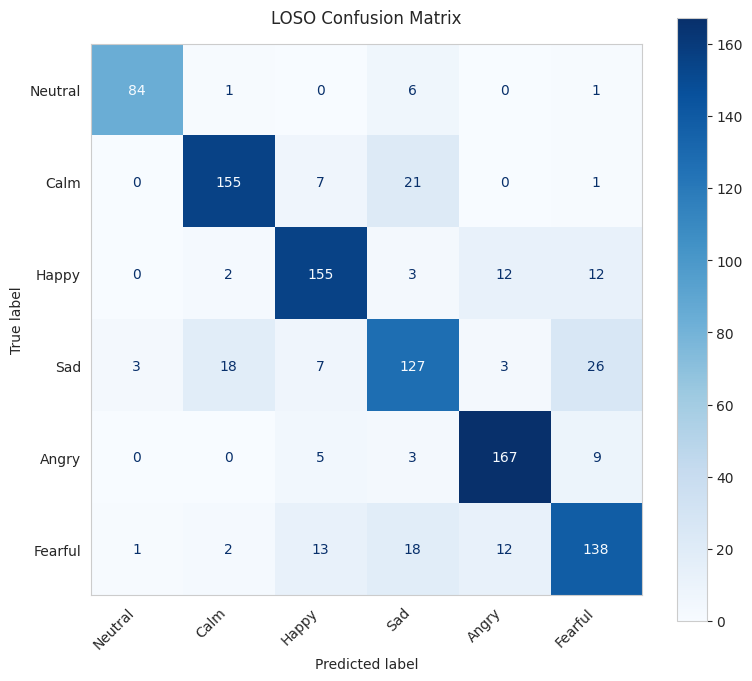

In [ ]:
# XGBoost expects 0 to N-1 labels
df_ravdess['emotion_xgb'] = df_ravdess['emotion'] - 1

xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    subsample=0.8,
    learning_rate=0.1,
    objective='multi:softprob',
    random_state=42,
    colsample_bytree=0.8
)

# loso evaluation
results_full = loso_evaluation(
    df_ravdess,
    feature_cols=all_features,
    model=xgb_model,
    target_col='emotion_xgb'
)

In [ ]:
actor_accuracies_full = [
    0.854, 0.979, 0.875, 0.812, 0.750, 0.875, 0.854, 0.812,
    0.771, 0.771, 0.896, 0.688, 0.792, 0.896, 0.875, 0.875,
    0.771, 0.708, 0.625, 0.917, 0.812, 0.812, 0.938
]

results = compute_bootstrap_ci(actor_accuracies_full, n_bootstraps=10000, ci=95.0)
print(results["formatted"])

CI: [78.98%, 85.68%])


## NESTED LOSO - feature selection

In [ ]:
def get_nested_loso_top_features(df, group_features, target_col, group_col='actor_id', top_n=10):
    """
    Nested LOSO feature selection using XGBoost.

    Returns:
        all_fold_preds: list of predicted labels for each outer test speaker
        all_fold_actuals: corresponding true labels
        fold_feature_sets: list of selected features per outer fold
    """
    le = LabelEncoder()
    y = le.fit_transform(df[target_col])
    X = df[group_features]
    groups = df[group_col]

    logo_outer = LeaveOneGroupOut()
    fold_feature_sets = []
    all_fold_preds = []
    all_fold_actuals = []

    print(f"Analyzing {len(group_features)} features over {groups.nunique()} speakers...")

    # OUTER LOOP: LOSO per speaker
    for fold_idx, (train_idx, test_idx) in enumerate(logo_outer.split(X, y, groups), 1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        train_groups = groups.iloc[train_idx]
        test_groups = groups.iloc[test_idx]
        test_speaker = np.unique(test_groups)[0]

        print(f"\n Fold {fold_idx} | Test speaker: {test_speaker}")

        # INNER FEATURE SELECTION (train speakers only)
        feature_counter = Counter()
        logo_inner = LeaveOneGroupOut()
        inner_train_indices = train_idx

        for inner_train_idx, inner_val_idx in logo_inner.split(X_train, y_train, train_groups):
            X_inner_train, y_inner_train = X_train.iloc[inner_train_idx], y_train[inner_train_idx]

            model_inner = xgb.XGBClassifier(
                n_estimators=100,
                max_depth=4,
                learning_rate=0.1,
                random_state=42,
                eval_metric='mlogloss'
            )
            model_inner.fit(X_inner_train, y_inner_train)

            # Feature importances
            importance = pd.Series(model_inner.feature_importances_, index=group_features)
            top_features = importance.nlargest(top_n).index.tolist()
            feature_counter.update(top_features)

        # Final selected features for this outer fold
        selected_features = [f for f, _ in feature_counter.most_common(top_n)]
        fold_feature_sets.append(selected_features)
        selected_indices = [group_features.index(f) for f in selected_features]

        print(f"   → Selected {len(selected_features)} features: {selected_features}")

    return fold_feature_sets


In [ ]:
result_prosodic = get_nested_loso_top_features(df_ravdess, prosodic, 'emotion', 'actor_id', 10)

Analyzing 43 features over 23 speakers...

 Fold 1 | Test speaker: 1
   → Selected 10 features: ['st_loudness_variability', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'shimmerLocaldB_sma3nz_amean', 'loudness_sma3_percentile80.0', 'loudness_sma3_meanRisingSlope', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'loudness_sma3_pctlrange0-2', 'loudnessPeaksPerSec', 'melodic_deviation', 'loudness_sma3_meanFallingSlope']

 Fold 2 | Test speaker: 2
   → Selected 10 features: ['st_loudness_variability', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'shimmerLocaldB_sma3nz_amean', 'loudness_sma3_meanRisingSlope', 'loudnessPeaksPerSec', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'loudness_sma3_percentile80.0', 'melodic_deviation', 'loudness_sma3_pctlrange0-2', 'loudness_sma3_meanFallingSlope']

 Fold 3 | Test speaker: 3
   → Selected 10 features: ['st_loudness_variability', 'shimmerLocaldB_sma3nz_amean', 'loudness_sma3_percentile80.0', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'loudness_sma3_meanRisi

In [ ]:
result_spectral = get_nested_loso_top_features(df_ravdess, spectral, 'emotion', 'actor_id', 10)

Analyzing 47 features over 23 speakers...

 Fold 1 | Test speaker: 1
   → Selected 10 features: ['HNRdBACF_sma3nz_amean', 'alphaRatioV_sma3nz_stddevNorm', 'spectralFluxV_sma3nz_amean', 'F3amplitudeLogRelF0_sma3nz_stddevNorm', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'spectralFlux_sma3_amean', 'alphaRatioV_sma3nz_amean', 'spectralFluxUV_sma3nz_amean', 'spectralFluxV_sma3nz_stddevNorm', 'logRelF0-H1-A3_sma3nz_amean']

 Fold 2 | Test speaker: 2
   → Selected 10 features: ['HNRdBACF_sma3nz_amean', 'alphaRatioV_sma3nz_stddevNorm', 'spectralFluxV_sma3nz_amean', 'F3amplitudeLogRelF0_sma3nz_stddevNorm', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'spectralFlux_sma3_amean', 'alphaRatioV_sma3nz_amean', 'spectralFluxUV_sma3nz_amean', 'logRelF0-H1-A3_sma3nz_amean', 'slopeV0-500_sma3nz_amean']

 Fold 3 | Test speaker: 3
   → Selected 10 features: ['HNRdBACF_sma3nz_amean', 'spectralFluxV_sma3nz_amean', 'alphaRatioV_sma3nz_stddevNorm', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'F3amplitudeLogRelF0_sma3nz

In [ ]:
result_tech = get_nested_loso_top_features(df_ravdess, techniques, 'emotion', 'actor_id', 10)

Analyzing 31 features over 23 speakers...

 Fold 1 | Test speaker: 1
   → Selected 10 features: ['pharyngeal_max', 'falsetto_max', 'pharyngeal_mean', 'breathy_max', 'glissando_max', 'MFDR_vibrato', 'vibrato_mean', 'breathy_mean', 'MFDR_high', 'pharyngeal_peak_factor']

 Fold 2 | Test speaker: 2
   → Selected 10 features: ['pharyngeal_max', 'falsetto_max', 'pharyngeal_mean', 'breathy_max', 'glissando_max', 'MFDR_vibrato', 'breathy_mean', 'pharyngeal_peak_factor', 'vibrato_mean', 'MFDR_high']

 Fold 3 | Test speaker: 3
   → Selected 10 features: ['pharyngeal_max', 'falsetto_max', 'pharyngeal_mean', 'glissando_max', 'breathy_max', 'breathy_mean', 'MFDR_vibrato', 'vibrato_mean', 'MFDR_high', 'pharyngeal_peak_factor']

 Fold 4 | Test speaker: 4
   → Selected 10 features: ['pharyngeal_max', 'pharyngeal_mean', 'falsetto_max', 'glissando_max', 'breathy_max', 'pharyngeal_peak_factor', 'MFDR_vibrato', 'breathy_mean', 'vibrato_mean', 'MFDR_high']

 Fold 5 | Test speaker: 5
   → Selected 10 featur

In [ ]:
result_phon = get_nested_loso_top_features(df_ravdess, phonemes, 'emotion', 'actor_id', 10)

Analyzing 9 features over 23 speakers...

 Fold 1 | Test speaker: 1
   → Selected 9 features: ['articulation_rate', 'mean_phoneme_duration', 'vowel_ratio', 'phoneme_duration_cv', 'std_phoneme_duration', 'pause_ratio', 'mean_pause_duration', 'avg_distance_pauses', 'std_pause_duration']

 Fold 2 | Test speaker: 2
   → Selected 9 features: ['articulation_rate', 'mean_phoneme_duration', 'vowel_ratio', 'phoneme_duration_cv', 'std_phoneme_duration', 'pause_ratio', 'mean_pause_duration', 'avg_distance_pauses', 'std_pause_duration']

 Fold 3 | Test speaker: 3
   → Selected 9 features: ['articulation_rate', 'mean_phoneme_duration', 'vowel_ratio', 'phoneme_duration_cv', 'pause_ratio', 'std_phoneme_duration', 'mean_pause_duration', 'avg_distance_pauses', 'std_pause_duration']

 Fold 4 | Test speaker: 4
   → Selected 9 features: ['mean_phoneme_duration', 'articulation_rate', 'vowel_ratio', 'phoneme_duration_cv', 'std_phoneme_duration', 'pause_ratio', 'mean_pause_duration', 'avg_distance_pauses', '

In [ ]:
results_all = get_nested_loso_top_features(df_ravdess, all_features, 'emotion', 'actor_id', 40)

Analyzing 130 features over 23 speakers...

 Fold 1 | Test speaker: 1
   → Selected 40 features: ['alphaRatioV_sma3nz_stddevNorm', 'loudness_sma3_percentile80.0', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'HNRdBACF_sma3nz_amean', 'loudness_sma3_meanFallingSlope', 'vowel_ratio', 'shimmerLocaldB_sma3nz_amean', 'st_loudness_variability', 'melodic_deviation', 'alphaRatioV_sma3nz_amean', 'articulation_rate', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'delta_energy_std', 'F3amplitudeLogRelF0_sma3nz_stddevNorm', 'loudnessPeaksPerSec', 'F0semitoneFrom27.5Hz_sma3nz_percentile50.0', 'F0semitoneFrom27.5Hz_sma3nz_amean', 'phoneme_duration_cv', 'breathy_mean', 'falsetto_max', 'loudness_sma3_pctlrange0-2', 'mean_phoneme_duration', 'spectralFlux_sma3_amean', 'spectralFluxV_sma3nz_amean', 'std_phoneme_duration', 'loudness_sma3_stddevFallingSlope', 'F0semitoneFrom27.5Hz_sma3nz_percentile20.0', 'F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2', 'loudness_sma3_percent

In [ ]:
best_prosodic = [
    'shimmerLocaldB_sma3nz_amean',
    'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0',
    'loudnessPeaksPerSec', 'melodic_deviation'
]
best_spectral = [
    'HNRdBACF_sma3nz_amean', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'alphaRatioV_sma3nz_stddevNorm',
    'spectralFlux_sma3_amean', 'alphaRatioV_sma3nz_amean'
]
best_phonemes = ['articulation_rate', 'std_phoneme_duration']

best_techniques = ['MFDR_vibrato', 'breathy_mean', 'pharyngeal_max',
    'falsetto_max', 'glissando_max', 'tech_entropy'
]

all_feats = best_prosodic + best_spectral + best_phonemes + best_techniques
print(len(best_prosodic), len(best_spectral), len(best_phonemes), len(best_techniques))
print(len(all_feats))


5 5 2 6
18


In [ ]:
# Calculate correlation for all selected features
corr_matrix = df_ravdess[all_feats].corr().abs()

# Filter to keep only the upper triangle (to avoid duplicate pairs)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Identify pairs with high correlation
high_corr_threshold = 0.9
to_drop = []
pairs = []

for column in upper.columns:
    for row in upper.index:
        if upper.loc[row, column] > high_corr_threshold:
            pairs.append({
                'Feature 1': row,
                'Feature 2': column,
                'Correlation': upper.loc[row, column]
            })
            # Add to the drop list (the second feature of the pair)
            if column not in to_drop:
                to_drop.append(column)

# Check if any pairs were found
if pairs:
    high_corr_df = pd.DataFrame(pairs).sort_values(by='Correlation', ascending=False)
    print(f"Found {len(high_corr_df)} pairs with correlation > {high_corr_threshold}")
    print(high_corr_df.head(20))
else:
    print(f"No feature pairs found with a correlation above {high_corr_threshold}.")

No feature pairs found with a correlation above 0.9.


## Evaluate the singing-optimized feature set

Starting Leave-One-Speaker-Out Evaluation...

Speaker 1 accuracy: 0.792
Speaker 2 accuracy: 0.875
Speaker 3 accuracy: 0.792
Speaker 4 accuracy: 0.812
Speaker 5 accuracy: 0.771
Speaker 6 accuracy: 0.812
Speaker 7 accuracy: 0.771
Speaker 8 accuracy: 0.688
Speaker 9 accuracy: 0.792
Speaker 10 accuracy: 0.875
Speaker 11 accuracy: 0.792
Speaker 12 accuracy: 0.688
Speaker 13 accuracy: 0.792
Speaker 14 accuracy: 0.875
Speaker 15 accuracy: 0.812
Speaker 16 accuracy: 0.812
Speaker 17 accuracy: 0.750
Speaker 19 accuracy: 0.646
Speaker 20 accuracy: 0.708
Speaker 21 accuracy: 0.896
Speaker 22 accuracy: 0.771
Speaker 23 accuracy: 0.750
Speaker 24 accuracy: 0.979

 Mean LOSO Balanced Accuracy: 0.793 and std: 0.073

Mean LOSO Macro-F1 Score: 0.788
Overall Classification Report:
              precision    recall  f1-score   support

     Neutral       0.90      0.87      0.88        92
        Calm       0.90      0.85      0.87       184
       Happy       0.77      0.80      0.79       184
         

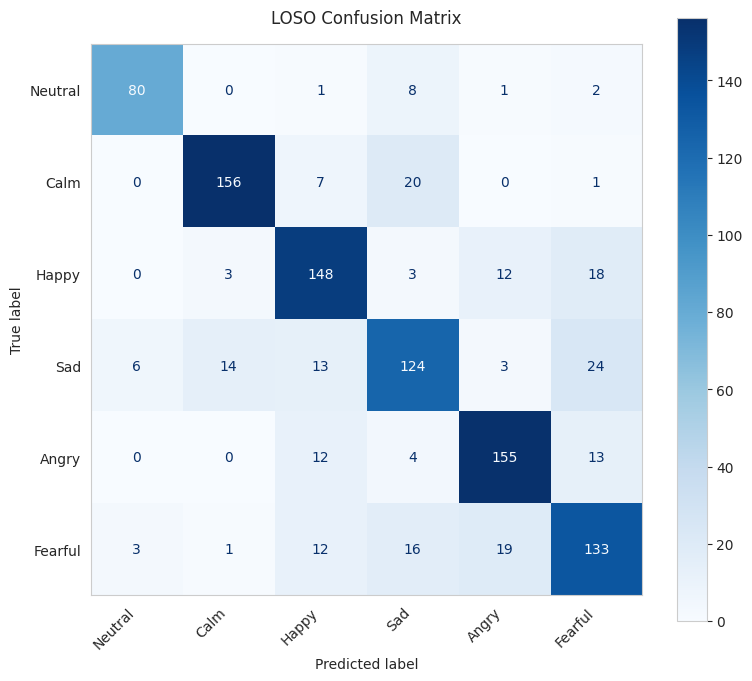

In [ ]:
df_ravdess['emotion_xgb'] = df_ravdess['emotion'] - 1

xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    subsample=0.8,
    learning_rate=0.1,
    objective='multi:softprob',
    random_state=42,
    colsample_bytree=0.8
)


results_sel = loso_evaluation(
    df_ravdess,
    feature_cols=all_feats,
    model=xgb_model,
    target_col='emotion_xgb'
)

In [ ]:
actor_accuracies_sing = [
    0.792, 0.875, 0.792, 0.812, 0.771, 0.812, 0.771, 0.688,
    0.792, 0.875, 0.792, 0.688, 0.792, 0.875, 0.812, 0.812,
    0.750, 0.646, 0.708, 0.896, 0.771, 0.750, 0.979
]
results = compute_bootstrap_ci(actor_accuracies_sing, n_bootstraps=10000, ci=95.0)
print(results["formatted"])

CI: [76.37%, 82.34%])


## Ablation study

In [ ]:
df_ravdess['emotion_xgb'] = df_ravdess['emotion'] - 1

# dictionary for ablation loop
categories = {
    'Prosodic': best_prosodic,
    'Spectral': best_spectral,
    'Phonemes': best_phonemes,
    'Techniques': best_techniques
}

all_selected_features = [f for sublist in categories.values() for f in sublist]
ablation_records = []

xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    subsample=0.8,
    learning_rate=0.1,
    objective='multi:softprob',
    random_state=42,
    colsample_bytree=0.8
)

# --- Scenario 1: Each category ALONE (Only One) ---
print("Running 'Only One' Ablation...")
for name, feats in categories.items():
    res = loso_evaluation(df_ravdess, feats, xgb_model, 'emotion_xgb', plot_cm=False)
    ablation_records.append({
        'Type': 'Single Category',
        'Experiment': f'Only {name}',
        'B. Accuracy': res['mean_bacc'],
        'Std': res['std_bacc']
    })

# --- Scenario 2: All categories EXCEPT for one (Leave-One-Out) ---
print("\n Running 'Leave-One-Out' Ablation...")
for name, feats in categories.items():
    current_feats = [f for f in all_selected_features if f not in feats]
    res = loso_evaluation(df_ravdess, current_feats, xgb_model, 'emotion_xgb', plot_cm=False)
    ablation_records.append({
        'Type': 'Leave-One-Out',
        'Experiment': f'All except {name}',
        'B. Accuracy': res['mean_bacc'],
        'Std': res['std_bacc']
    })


Running 'Only One' Ablation...
Starting Leave-One-Speaker-Out Evaluation...

Speaker 1 accuracy: 0.604
Speaker 2 accuracy: 0.708
Speaker 3 accuracy: 0.583
Speaker 4 accuracy: 0.750
Speaker 5 accuracy: 0.708
Speaker 6 accuracy: 0.792
Speaker 7 accuracy: 0.646
Speaker 8 accuracy: 0.562
Speaker 9 accuracy: 0.521
Speaker 10 accuracy: 0.729
Speaker 11 accuracy: 0.750
Speaker 12 accuracy: 0.792
Speaker 13 accuracy: 0.771
Speaker 14 accuracy: 0.625
Speaker 15 accuracy: 0.688
Speaker 16 accuracy: 0.729
Speaker 17 accuracy: 0.667
Speaker 19 accuracy: 0.417
Speaker 20 accuracy: 0.562
Speaker 21 accuracy: 0.750
Speaker 22 accuracy: 0.625
Speaker 23 accuracy: 0.438
Speaker 24 accuracy: 0.854

 Mean LOSO Balanced Accuracy: 0.664 and std: 0.111

Overall Classification Report:
              precision    recall  f1-score   support

     Neutral       0.87      0.84      0.85        92
        Calm       0.80      0.79      0.79       184
       Happy       0.67      0.68      0.68       184
         S

In [ ]:
df_ablation = pd.DataFrame(ablation_records)
print("\nFINAL ABLATION RESULTS")
display(df_ablation.sort_values(by=['Type'], ascending=False))


FINAL ABLATION RESULTS


,Type,Experiment,B. Accuracy,Std
0,Single Category,Only Prosodic,0.663949,0.110804
1,Single Category,Only Spectral,0.535326,0.108416
2,Single Category,Only Phonemes,0.327899,0.099101
3,Single Category,Only Techniques,0.349638,0.085779
4,Leave-One-Out,All except Prosodic,0.624094,0.080916
5,Leave-One-Out,All except Spectral,0.731884,0.100065
6,Leave-One-Out,All except Phonemes,0.772645,0.066142
7,Leave-One-Out,All except Techniques,0.795290,0.076891


## Speech-Optimized Set Evaluation

In [ ]:
prosodic = ['F0semitoneFrom27.5Hz_sma3nz_amean', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm',
            'F0semitoneFrom27.5Hz_sma3nz_percentile20.0', 'F0semitoneFrom27.5Hz_sma3nz_percentile50.0',
            'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2',
            'F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope', 'F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope',
            'F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope', 'F0semitoneFrom27.5Hz_sma3nz_stddevFallingSlope',
            'loudness_sma3_amean', 'loudness_sma3_stddevNorm', 'loudness_sma3_percentile20.0',
            'loudness_sma3_percentile50.0', 'loudness_sma3_percentile80.0', 'loudness_sma3_pctlrange0-2',
            'loudness_sma3_meanRisingSlope', 'loudness_sma3_stddevRisingSlope', 'loudness_sma3_meanFallingSlope',
            'loudness_sma3_stddevFallingSlope', 'loudnessPeaksPerSec', 'VoicedSegmentsPerSec',
            'MeanVoicedSegmentLengthSec', 'StddevVoicedSegmentLengthSec', 'MeanUnvoicedSegmentLength',
            'StddevUnvoicedSegmentLength', 'equivalentSoundLevel_dBp',
            'jitterLocal_sma3nz_amean',
            'jitterLocal_sma3nz_stddevNorm', 'shimmerLocaldB_sma3nz_amean', 'shimmerLocaldB_sma3nz_stddevNorm']

spectral = ['spectralFlux_sma3_amean', 'spectralFlux_sma3_stddevNorm',
            'HNRdBACF_sma3nz_amean', 'HNRdBACF_sma3nz_stddevNorm', 'logRelF0-H1-H2_sma3nz_amean',
            'logRelF0-H1-H2_sma3nz_stddevNorm', 'logRelF0-H1-A3_sma3nz_amean', 'logRelF0-H1-A3_sma3nz_stddevNorm',
            'F1frequency_sma3nz_amean', 'F1frequency_sma3nz_stddevNorm', 'F1bandwidth_sma3nz_amean',
            'F1bandwidth_sma3nz_stddevNorm', 'F1amplitudeLogRelF0_sma3nz_amean', 'F1amplitudeLogRelF0_sma3nz_stddevNorm',
            'F2frequency_sma3nz_amean', 'F2frequency_sma3nz_stddevNorm', 'F2bandwidth_sma3nz_amean',
            'F2bandwidth_sma3nz_stddevNorm', 'F2amplitudeLogRelF0_sma3nz_amean', 'F2amplitudeLogRelF0_sma3nz_stddevNorm',
            'F3frequency_sma3nz_amean', 'F3frequency_sma3nz_stddevNorm', 'F3bandwidth_sma3nz_amean',
            'F3bandwidth_sma3nz_stddevNorm', 'F3amplitudeLogRelF0_sma3nz_amean', 'F3amplitudeLogRelF0_sma3nz_stddevNorm',
            'alphaRatioV_sma3nz_amean', 'alphaRatioV_sma3nz_stddevNorm', 'hammarbergIndexV_sma3nz_amean',
            'hammarbergIndexV_sma3nz_stddevNorm', 'slopeV0-500_sma3nz_amean', 'slopeV0-500_sma3nz_stddevNorm',
            'slopeV500-1500_sma3nz_amean', 'slopeV500-1500_sma3nz_stddevNorm', 'spectralFluxV_sma3nz_amean',
            'spectralFluxV_sma3nz_stddevNorm', 'alphaRatioUV_sma3nz_amean', 'hammarbergIndexUV_sma3nz_amean',
            'slopeUV0-500_sma3nz_amean', 'slopeUV500-1500_sma3nz_amean', 'spectralFluxUV_sma3nz_amean'
            ]
phonemes = ['phoneme_duration_cv',
            'articulation_rate',
            'vowel_ratio',
            'consonant_ratio',
            'avg_distance_pauses',
            'mean_pause_dur',
            'std_pause_dur',
            'mean_phoneme_duration',
            'std_phoneme_duration',
            'pause_ratio']

all = prosodic + spectral + phoneme

In [ ]:
result_prosodic = get_nested_loso_top_features(df_ravdess, prosodic, 'emotion', 'actor_id', 10)

Analyzing 31 features over 23 speakers...

 Fold 1 | Test speaker: 1
   → Selected 10 features: ['loudness_sma3_pctlrange0-2', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'loudness_sma3_percentile80.0', 'shimmerLocaldB_sma3nz_amean', 'loudness_sma3_meanRisingSlope', 'loudnessPeaksPerSec', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'loudness_sma3_meanFallingSlope', 'F0semitoneFrom27.5Hz_sma3nz_amean', 'equivalentSoundLevel_dBp']

 Fold 2 | Test speaker: 2
   → Selected 10 features: ['loudness_sma3_pctlrange0-2', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'loudness_sma3_percentile80.0', 'shimmerLocaldB_sma3nz_amean', 'loudness_sma3_meanRisingSlope', 'loudnessPeaksPerSec', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'F0semitoneFrom27.5Hz_sma3nz_amean', 'loudness_sma3_meanFallingSlope', 'equivalentSoundLevel_dBp']

 Fold 3 | Test speaker: 3
   → Selected 10 features: ['F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'loudness_sma3_percentile80.0', 'shimmerLocaldB_sma3nz_amean', 'loudness_sma3_m

In [ ]:
result_spectral = get_nested_loso_top_features(df_ravdess, spectral, 'emotion', 'actor_id', 10)

Analyzing 41 features over 23 speakers...

 Fold 1 | Test speaker: 1
   → Selected 10 features: ['HNRdBACF_sma3nz_amean', 'alphaRatioV_sma3nz_stddevNorm', 'spectralFluxV_sma3nz_amean', 'F3amplitudeLogRelF0_sma3nz_stddevNorm', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'alphaRatioV_sma3nz_amean', 'spectralFlux_sma3_amean', 'spectralFluxUV_sma3nz_amean', 'logRelF0-H1-A3_sma3nz_amean', 'spectralFluxV_sma3nz_stddevNorm']

 Fold 2 | Test speaker: 2
   → Selected 10 features: ['HNRdBACF_sma3nz_amean', 'alphaRatioV_sma3nz_stddevNorm', 'spectralFluxV_sma3nz_amean', 'F3amplitudeLogRelF0_sma3nz_stddevNorm', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'alphaRatioV_sma3nz_amean', 'spectralFlux_sma3_amean', 'spectralFluxUV_sma3nz_amean', 'logRelF0-H1-A3_sma3nz_amean', 'slopeV0-500_sma3nz_amean']

 Fold 3 | Test speaker: 3
   → Selected 10 features: ['HNRdBACF_sma3nz_amean', 'spectralFluxV_sma3nz_amean', 'alphaRatioV_sma3nz_stddevNorm', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'F3amplitudeLogRelF0_sma3nz

In [ ]:
result_all = get_nested_loso_top_features(df_ravdess, all, 'emotion', 'actor_id', 40)

Analyzing 74 features over 23 speakers...

 Fold 1 | Test speaker: 1
   → Selected 40 features: ['loudness_sma3_pctlrange0-2', 'loudness_sma3_percentile80.0', 'alphaRatioV_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'HNRdBACF_sma3nz_amean', 'shimmerLocaldB_sma3nz_amean', 'loudness_sma3_meanFallingSlope', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'articulation_rate', 'loudnessPeaksPerSec', 'alphaRatioV_sma3nz_amean', 'F3amplitudeLogRelF0_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_amean', 'spectralFlux_sma3_amean', 'F0semitoneFrom27.5Hz_sma3nz_percentile50.0', 'hammarbergIndexV_sma3nz_stddevNorm', 'spectralFluxV_sma3nz_amean', 'std_phoneme_duration', 'logRelF0-H1-A3_sma3nz_amean', 'loudness_sma3_meanRisingSlope', 'F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2', 'equivalentSoundLevel_dBp', 'F0semitoneFrom27.5Hz_sma3nz_percentile20.0', 'spectralFluxUV_sma3nz_amean', 'loudness_sma3_stddevNorm', 'F1frequency_sma3nz_amean', 'loud

In [ ]:
spectral = ['HNRdBACF_sma3nz_amean', 'alphaRatioV_sma3nz_stddevNorm',
            'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'alphaRatioV_sma3nz_amean', 'spectralFluxUV_sma3nz_amean', 'F1bandwidth_sma3nz_stddevNorm',
            'logRelF0-H1-A3_sma3nz_amean', 'slopeV0-500_sma3nz_amean', 'F2frequency_sma3nz_stddevNorm']

phoneme = ['articulation_rate', 'std_phoneme_duration']

prosodic = ['loudness_sma3_percentile80.0', 'loudnessPeaksPerSec',
            'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_amean', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'shimmerLocaldB_sma3nz_amean',
            'shimmerLocaldB_sma3nz_stddevNorm', 'MeanVoicedSegmentLengthSec']

speech = prosodic + spectral + phoneme

In [ ]:
len(speech)

19

In [ ]:
# 1. Calculate correlation for all selected features
corr_matrix = df_ravdess[speech].corr().abs()

# 2. Filter to keep only the upper triangle (to avoid duplicate pairs)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# 3. Identify pairs with high correlation
high_corr_threshold = 0.9
to_drop = []
pairs = []

for column in upper.columns:
    for row in upper.index:
        if upper.loc[row, column] > high_corr_threshold:
            pairs.append({
                'Feature 1': row,
                'Feature 2': column,
                'Correlation': upper.loc[row, column]
            })
            # Add to the drop list (the second feature of the pair)
            if column not in to_drop:
                to_drop.append(column)

# Check if any pairs were found
if pairs:
    high_corr_df = pd.DataFrame(pairs).sort_values(by='Correlation', ascending=False)
    print(f"Found {len(high_corr_df)} pairs with correlation > {high_corr_threshold}")
    print(high_corr_df.head(20))
else:
    print(f"No feature pairs found with a correlation above {high_corr_threshold}.")

No feature pairs found with a correlation above 0.9.


Starting Leave-One-Speaker-Out Evaluation...

Speaker 1 accuracy: 0.792
Speaker 2 accuracy: 0.875
Speaker 3 accuracy: 0.771
Speaker 4 accuracy: 0.917
Speaker 5 accuracy: 0.750
Speaker 6 accuracy: 0.771
Speaker 7 accuracy: 0.833
Speaker 8 accuracy: 0.750
Speaker 9 accuracy: 0.583
Speaker 10 accuracy: 0.833
Speaker 11 accuracy: 0.958
Speaker 12 accuracy: 0.667
Speaker 13 accuracy: 0.792
Speaker 14 accuracy: 0.854
Speaker 15 accuracy: 0.833
Speaker 16 accuracy: 0.833
Speaker 17 accuracy: 0.729
Speaker 19 accuracy: 0.562
Speaker 20 accuracy: 0.604
Speaker 21 accuracy: 0.958
Speaker 22 accuracy: 0.812
Speaker 23 accuracy: 0.708
Speaker 24 accuracy: 0.938

 Mean LOSO Balanced Accuracy: 0.788 and std: 0.109

Mean LOSO Macro-F1 Score: 0.783
Overall Classification Report:
              precision    recall  f1-score   support

     Neutral       0.89      0.86      0.87        92
        Calm       0.84      0.80      0.82       184
       Happy       0.81      0.82      0.81       184
         

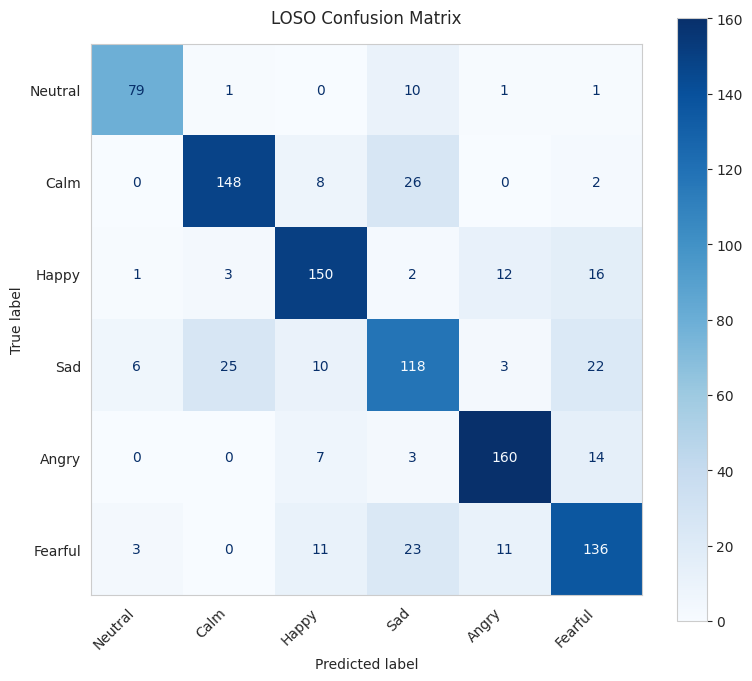

In [ ]:
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    subsample=0.8,
    learning_rate=0.1,
    objective='multi:softprob',
    random_state=42,
    colsample_bytree=0.8
)

# loso evaluation
results_full = loso_evaluation(
    df_ravdess,
    feature_cols=speech,
    model=xgb_model,
    target_col='emotion_xgb'
)

In [ ]:
actor_accuracies_speech = [
    0.792, 0.875, 0.771, 0.917, 0.750, 0.771, 0.833, 0.750,
    0.583, 0.833, 0.958, 0.667, 0.792, 0.854, 0.833, 0.833,
    0.729, 0.562, 0.604, 0.958, 0.812, 0.708, 0.938
]
results = compute_bootstrap_ci(actor_accuracies_speech, n_bootstraps=10000, ci=95.0)
print(results["formatted"])

CI: [74.27%, 83.05%])


In [ ]:
def compute_std_ratio_ci(speech_data, singing_data, n_bootstraps=10000, ci=95.0, seed=42):
    speech_data = np.asarray(speech_data)
    singing_data = np.asarray(singing_data)
    n_samples = len(speech_data)

    if seed is not None:
        np.random.seed(seed)

    # Paired resampling across speakers
    boot_indices = np.random.choice(n_samples, size=(n_bootstraps, n_samples), replace=True)

    # Standard deviations across resamples
    speech_stds = np.std(speech_data[boot_indices], axis=1, ddof=1)
    singing_stds = np.std(singing_data[boot_indices], axis=1, ddof=1)

    # Ratio array
    std_ratios = singing_stds / speech_stds

    # Percentiles
    lower_p = (100.0 - ci) / 2.0
    upper_p = 100.0 - lower_p

    orig_ratio = np.std(singing_data, ddof=1) / np.std(speech_data, ddof=1)
    lower_bound = np.percentile(std_ratios, lower_p)
    upper_bound = np.percentile(std_ratios, upper_p)

    return {
        "std_ratio": orig_ratio,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "formatted": f"Ratio: {orig_ratio:.4f} ({ci:.0f}% CI: [{lower_bound:.4f}, {upper_bound:.4f}])"
    }

# Compute and print ratio CI
results = compute_std_ratio_ci(actor_accuracies_speech, actor_accuracies_sing)
print(results["formatted"])

Ratio: 0.6714 (95% CI: [0.4706, 0.9116])


## Shap analysis of the Singing-Optmizized Model

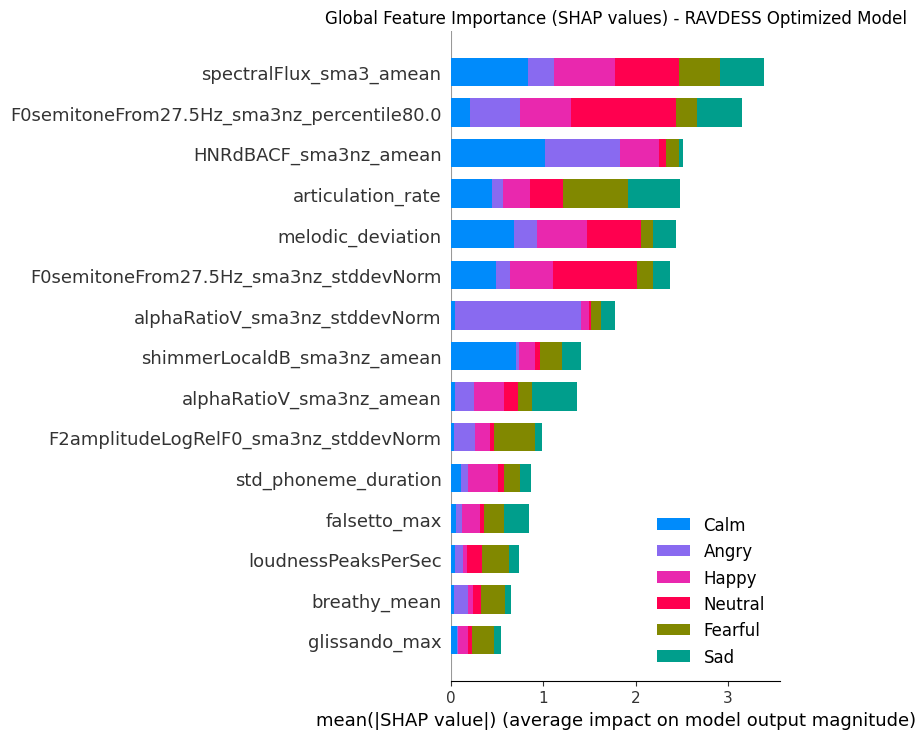

In [ ]:
final_xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    subsample=0.8,
    learning_rate=0.1,
    objective='multi:softprob',
    random_state=42,
    colsample_bytree=0.8
)

X_final = df_ravdess[all_feats].values
y_final = df_ravdess['emotion_xgb'].values

# 1. Fit final model
final_xgb_model.fit(df_ravdess[all_feats], y_final)

# 2. Compute SHAP values
explainer = shap.TreeExplainer(final_xgb_model)
shap_values = explainer.shap_values(df_ravdess[all_feats])

# 3. Shap summary plot
plt.figure(figsize=(12, 8))
emotion_names = ['Neutral', 'Calm', 'Happy', 'Sad', 'Angry', 'Fearful']

shap.summary_plot(
    shap_values,
    df_ravdess[all_feats],
    plot_type="bar",
    class_names=emotion_names,
    max_display=15, # show the 15 most important feats
    show=False
)

plt.title("Global Feature Importance (SHAP values) - RAVDESS Optimized Model")
plt.tight_layout()
plt.show()

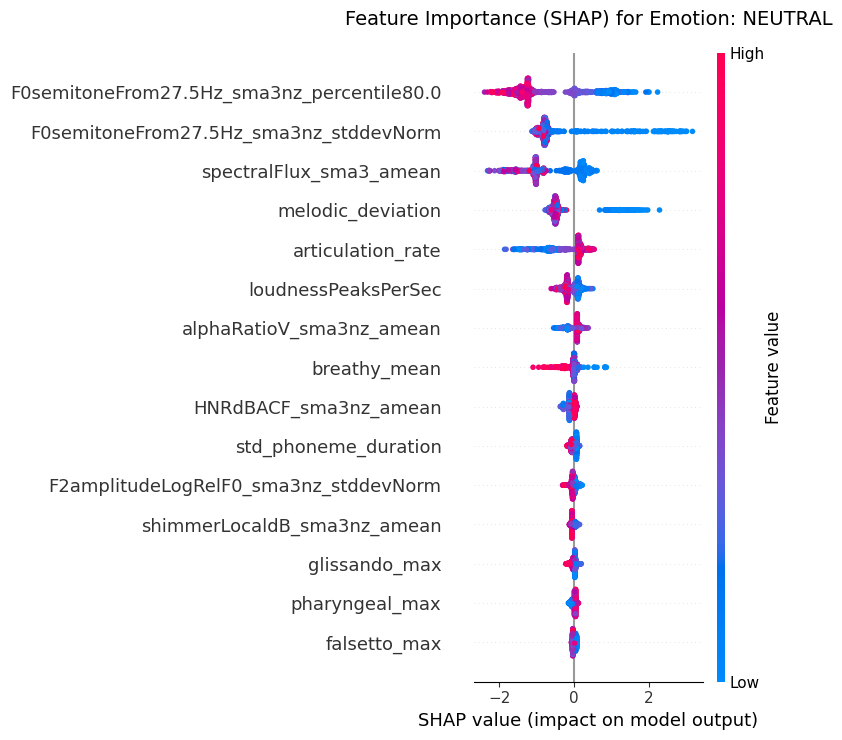

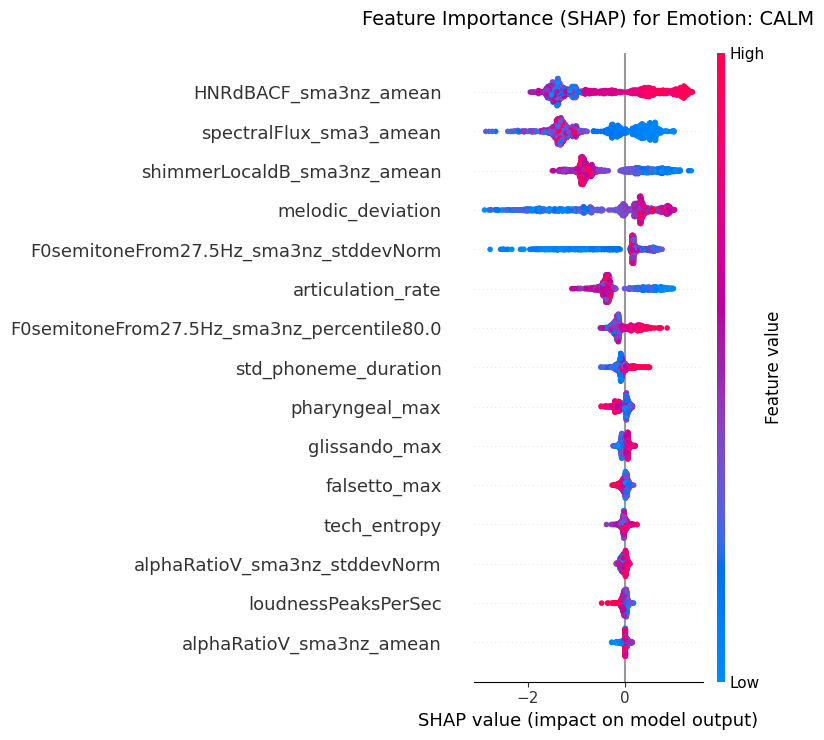

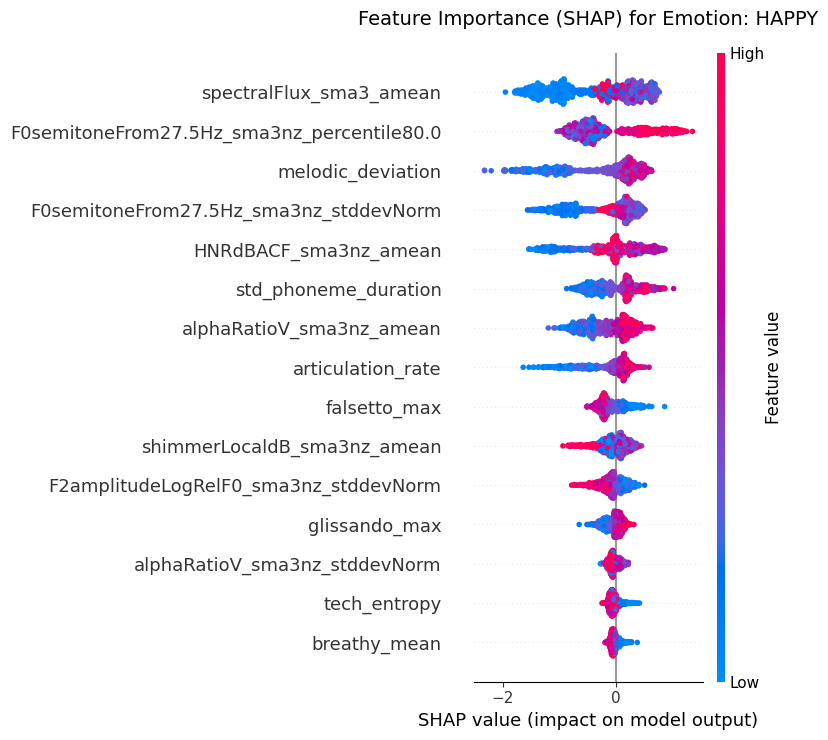

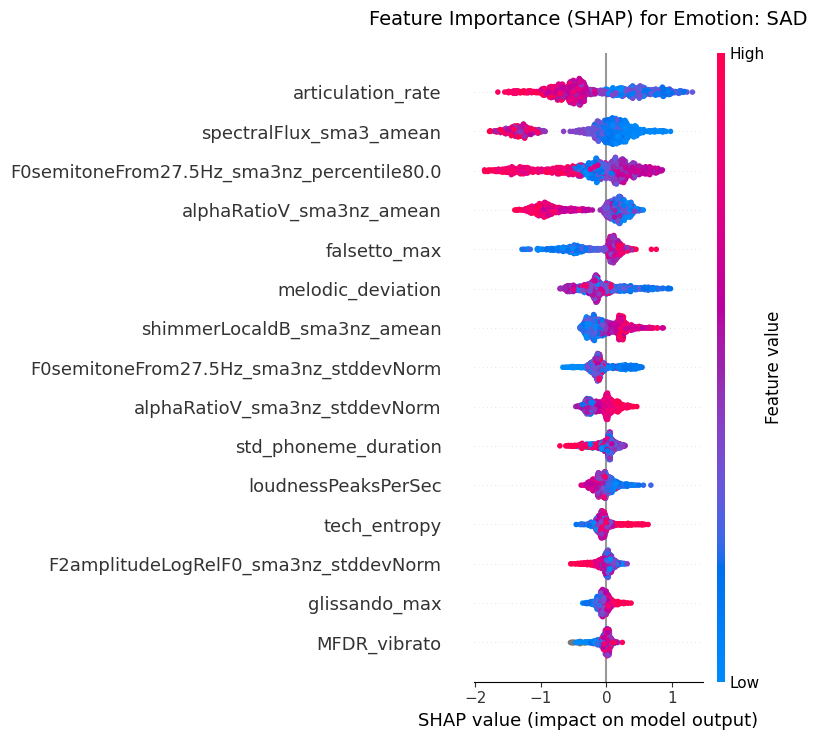

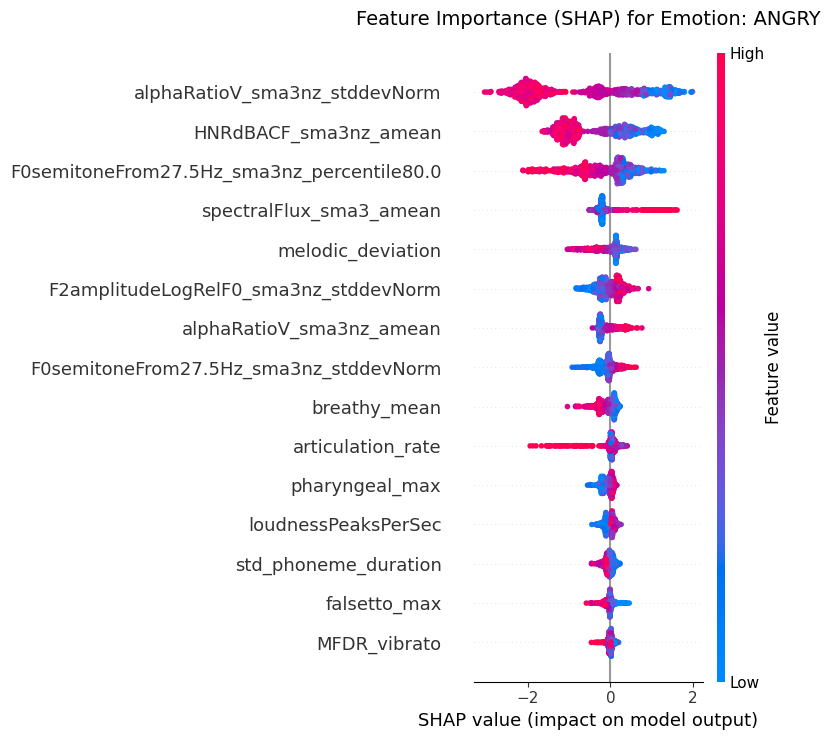

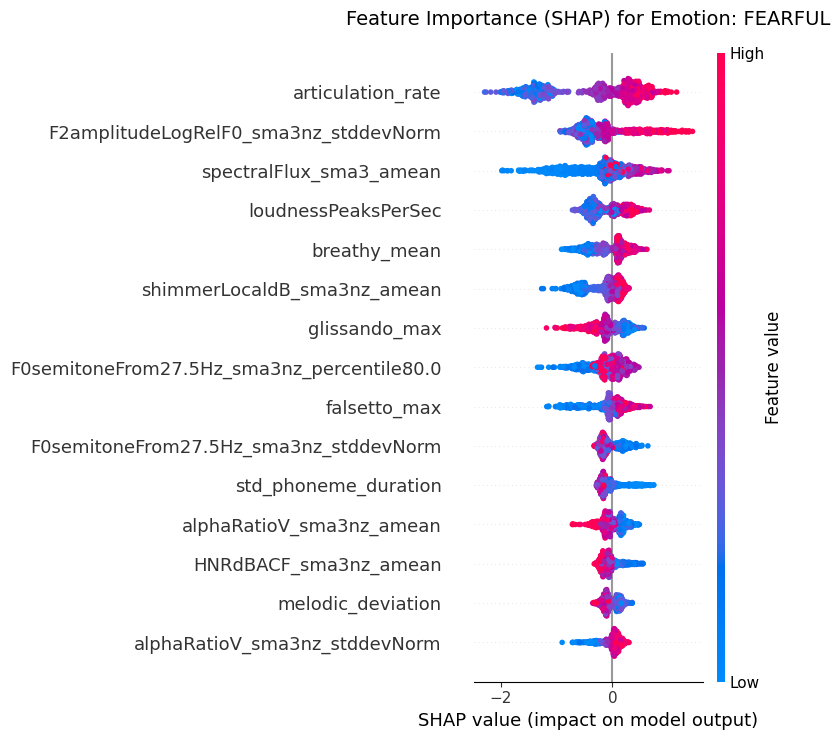

In [ ]:
X_final_df = df_ravdess[all_feats]

explainer = shap.TreeExplainer(final_xgb_model)
shap_values = explainer.shap_values(X_final_df)

emotion_names = ['Neutral', 'Calm', 'Happy', 'Sad', 'Angry', 'Fearful']

# Loop to create a summary plot for each emotion
for i, name in enumerate(emotion_names):
    plt.figure(figsize=(10, 6))

    if isinstance(shap_values, list):
        current_shap_values = shap_values[i]
    else:
        current_shap_values = shap_values[:, :, i]

    plt.title(f"Feature Importance (SHAP) for Emotion: {name.upper()}", fontsize=14, pad=20)

    shap.summary_plot(
        current_shap_values,
        X_final_df,
        feature_names=all_feats,
        max_display=15,
        plot_type="dot",   # Dot plot to visualize the impact of feature values (high/low)
        show=False
    )

    plt.tight_layout()
    plt.show()

In [ ]:
import joblib
emotion_names = ['Neutral', 'Calm', 'Happy', 'Sad', 'Angry', 'Fearful']

production_package = {
    'model': final_xgb_model,
    'feature_names': all_feats,
    'class_names': emotion_names
}

save_path = '/content/drive/MyDrive/ravdess_singing_opt_model.pkl'
joblib.dump(production_package, save_path)

print(f"Model saved succesfully at: {save_path}")

Model saved succesfully at: /content/drive/MyDrive/ravdess_singing_opt_model.pkl


In [ ]:
final_xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    subsample=0.8,
    learning_rate=0.1,
    objective='multi:softprob',
    random_state=42,
    colsample_bytree=0.8
)

X_final = df_ravdess[speech].values
y_final = df_ravdess['emotion_xgb'].values

final_xgb_model.fit(df_ravdess[speech], y_final)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
production_package = {
    'model': final_xgb_model,
    'feature_names': speech,
    'class_names': emotion_names
}

save_path = '/content/drive/MyDrive/ravdess_speech_opt_model.pkl'
joblib.dump(production_package, save_path)

print(f"Model saved succesfully at: {save_path}")

Model saved succesfully at: /content/drive/MyDrive/ravdess_speech_opt_model.pkl


# VocalSet

In [ ]:
df_vocalset = pd.read_csv('vocalset_final_check.csv')

In [ ]:
df_vocalset.technique.value_counts()

,count
technique,
slow_piano,393
fast_piano,358
fast_forte,338
straight,287
belt,190
trill,183
breathy,175
vibrato,175
lip_trill,159


In [ ]:
df_vocalset.shape

(2553, 151)

## Grad-cam Analysis of Vocal Technique Extractor

In [ ]:
model = tf.keras.models.load_model("model_pitch_leaky (1).h5")
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ spectrogram_input   │ (None, 160, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 160, 128,  │        320 │ spectrogram_inpu… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 128,  │        128 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 80, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout2d_6 │ (None, 80, 64,    │          0 │ max_pooling2d_6[… │
│ (SpatialDropout2D)  │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pitch_input         │ (None, 128, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 80, 64,    │     18,496 │ spatial_dropout2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 128, 32)   │        384 │ pitch_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 80, 64,    │        256 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 32)   │        128 │ conv1d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 40, 32,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 128, 64)   │      6,208 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout2d_7 │ (None, 40, 32,    │          0 │ max_pooling2d_7[… │
│ (SpatialDropout2D)  │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 128, 64)   │          0 │ conv1d_7[0][0]    │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ spatial_dropout2… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ spatial_dropout2… │
│ (GlobalMaxPooling2… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 64)   │        256 │ leaky_re_lu_1[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 60,040 (234.54 KB)

 Trainable params: 59,398 (232.02 KB)

 Non-trainable params: 640 (2.50 KB)

 Optimizer params: 2 (12.00 B)

In [ ]:
target_sr = 22050
n_mels = 160
hop_length = 256
n_fft = 2048
target_frames = 128
target_samples = target_frames * hop_length
techniques = ['mix', 'falsetto', 'breathy', 'pharyngeal', 'glissando', 'vibrato']

In [ ]:
def extract_audio_chunks(wav_path):
    """
    Loads an audio file, splits it into fixed-size frames, and extracts normalized
    Mel-Spectrograms and YIN f0 pitch contours.
    """
    target_samples = target_frames * hop_length

    y, _ = librosa.load(wav_path, sr=target_sr)
    total_samples = len(y)

    mel_chunks = []
    pitch_chunks = []
    times = []

    fmin = librosa.note_to_hz('C2')
    fmax = librosa.note_to_hz('C7')

    for start_sample in range(0, total_samples, target_samples):
        end_sample = start_sample + target_samples
        chunk_audio = y[start_sample:end_sample]

        # Handle shorter chunks at the end
        if len(chunk_audio) < target_samples:
            if len(chunk_audio) / target_samples < 0.3:
                continue
            chunk_audio = np.pad(
                chunk_audio,
                (0, target_samples - len(chunk_audio)),
                mode='constant'
            )

        # Mel-Spectrogram Extraction & Normalization
        S = librosa.feature.melspectrogram(
            y=chunk_audio,
            sr=target_sr,
            n_mels=n_mels,
            n_fft=n_fft,
            hop_length=hop_length
        )
        S_dB = librosa.power_to_db(S, ref=np.max)

        if S_dB.shape[1] > target_frames:
            S_dB = S_dB[:, :target_frames]
        elif S_dB.shape[1] < target_frames:
            S_dB = np.pad(S_dB, ((0, 0), (0, target_frames - S_dB.shape[1])))

        S_norm = np.clip((S_dB + 80) / 80, 0, 1)

        # Pitch (YIN) Extraction & Normalization
        f0 = librosa.yin(
            y=chunk_audio,
            fmin=fmin,
            fmax=fmax,
            sr=target_sr,
            hop_length=hop_length
        )
        f0_norm = np.clip(f0 / fmax, 0, 1)

        if len(f0_norm) > target_frames:
            f0_norm = f0_norm[:target_frames]
        elif len(f0_norm) < target_frames:
            f0_norm = np.pad(f0_norm, (0, target_frames - len(f0_norm)))

        mel_chunks.append(S_norm)
        pitch_chunks.append(f0_norm)
        times.append(start_sample / target_sr)

    # Convert to standard model input shapes (N, H, W, C) / (N, W, C)
    X_m = np.array(mel_chunks)[..., np.newaxis] if mel_chunks else np.empty((0, n_mels, target_frames, 1))
    X_p = np.array(pitch_chunks)[..., np.newaxis] if pitch_chunks else np.empty((0, target_frames, 1))

    return X_m, X_p, times

In [ ]:
def analyze_vocal_track(X_m, X_p, times, model):
    """
    Executes Inference and Visualization.
    """
    print("--- Running Model Prediction ---")
    predictions = model.predict([X_m, X_p], verbose=0)

    data_list = []
    for i in range(len(times)):
        row = {'timestamp': times[i]}
        for j, tech in enumerate(techniques):
            row[tech] = predictions[i][j]
        data_list.append(row)

    df_results = pd.DataFrame(data_list)

    # Visualisation
    sns.set_style("whitegrid")
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

    clip_duration = target_samples / target_sr

    x_steps = list(df_results['timestamp']) + [df_results['timestamp'].iloc[-1] + clip_duration]

    def get_step_values(col_name):
        return list(df_results[col_name]) + [df_results[col_name].iloc[-1]]

    # Plot 1
    ax1.step(x_steps, get_step_values('pharyngeal'), where='post', label='Pharyngeal', color='#d62728', linewidth=2.5)
    ax1.step(x_steps, get_step_values('mix'), where='post', label='Mix', color='#1f77b4', linewidth=3)
    ax1.step(x_steps, get_step_values('falsetto'), where='post', label='Falsetto', color='#ff7f0e', linewidth=3)
    ax1.axhline(y=0.4, color='gray', linestyle='--', alpha=0.5)
    ax1.set_ylabel("Probability")
    ax1.legend(loc='upper right')
    ax1.set_ylim(0, 1)

    # Plot 2
    ax2.step(x_steps, get_step_values('breathy'), where='post', label='Breathy', color='#2ca02c', linewidth=2.5)
    ax2.step(x_steps, get_step_values('glissando'), where='post', label='Glissando', color='#9467bd', linewidth=2.5)
    ax2.step(x_steps, get_step_values('vibrato'), where='post', label='Vibrato', color='#8c564b', linewidth=3)
    ax2.axhline(y=0.4, color='gray', linestyle='--', alpha=0.5)
    ax2.set_ylabel("Probability")
    ax2.set_xlabel("Time (seconds)")
    ax2.legend(loc='upper right')
    ax2.set_ylim(0, 1)

    plt.xticks(x_steps, [f"{x:.2f}" for x in x_steps], rotation=45)

    plt.tight_layout()
    plt.show()

    return df_results


In [ ]:
def get_gradcam_multi(model, mel_input, pitch_input, layer_name, class_idx):
    class_names = ['mix', 'falsetto', 'breathy', 'pharyngeal', 'glissando', 'vibrato']
    if isinstance(class_idx, str):
        class_idx = class_names.index(class_idx)

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        model_outputs = grad_model([mel_input, pitch_input])
        conv_output_tensor = model_outputs[0]
        predictions_tensor = model_outputs[1]

        if isinstance(predictions_tensor, list):
            predictions_tensor = predictions_tensor[0]

        loss = predictions_tensor[:, class_idx]

    # Compute Gradients
    grads = tape.gradient(loss, conv_output_tensor)

    # Separate 2D (Spectrogram) and 1D (Pitch) branches
    dims = len(grads.shape)

    if dims == 4:
        weights = tf.reduce_mean(grads, axis=(0, 1, 2))
        output = conv_output_tensor[0].numpy()
        weights = weights.numpy()
        cam = np.dot(output, weights)
    elif dims == 3:
        weights = tf.reduce_mean(grads, axis=(0, 1))
        output = conv_output_tensor[0].numpy()
        weights = weights.numpy()
        cam = np.dot(output, weights)
    else:
        raise ValueError(f"Unexpected layer dimensions: {dims}")

    # ReLU and Normalization
    cam = np.maximum(cam, 0)
    if np.max(cam) > 0:
        cam = cam / np.max(cam)

    return cam

In [ ]:
def plot_gradcam_grid(
    model,
    X_m,
    X_p,
    times,
    class_idx,
    class_label,
    layer_name='conv2d_7',
    max_chunks=6,
    alpha=0.45
):
    """
    Computes Grad-CAM heatmaps for audio chunks and plots a grid of overlays.
    """
    def draw_gradcam_on_ax(ax, mel_data, heatmap, title):
        heatmap_resized = cv2.resize(heatmap, (mel_data.shape[1], mel_data.shape[0]))
        ax.imshow(mel_data[:, :, 0], aspect='auto', origin='lower', cmap='viridis')
        im = ax.imshow(heatmap_resized, aspect='auto', origin='lower', cmap='jet', alpha=alpha)

        ax.set_title(title, fontsize=10)
        ax.set_xlabel("Time Frames", fontsize=8)
        ax.set_ylabel("Mel Bins", fontsize=8)
        ax.grid(False)
        return im

    # Calculate grid layout
    num_chunks = min(max_chunks, len(X_m))
    cols = 3
    rows = int(np.ceil(max_chunks / cols))

    fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
    axes = axes.flatten()

    im_plot = None

    for i in range(max_chunks):
        if i < num_chunks:
            single_mel = np.expand_dims(X_m[i], axis=0)
            single_pitch = np.expand_dims(X_p[i], axis=0)

            try:
                heatmap_mel = get_gradcam_multi(model, single_mel, single_pitch, layer_name, class_idx)
                title_str = f"Chunk {i+1} ({times[i]:.2f}s)"
                im_plot = draw_gradcam_on_ax(axes[i], X_m[i], heatmap_mel, title=title_str)
            except Exception as e:
                axes[i].text(0.5, 0.5, f"Error:\n{e}", ha='center', va='center')
                axes[i].set_title(f"Chunk {i+1} - Failed")
        else:
            # Turn off unused subplot axes (e.g., if there are only 5 chunks)
            axes[i].axis('off')

    # Add shared colorbar if at least one subplot succeeded
    if im_plot is not None:
        fig.subplots_adjust(right=0.92, hspace=0.3, wspace=0.2)
        cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
        fig.colorbar(im_plot, cax=cbar_ax, label="Importance Score")

    plt.suptitle(
        f"Grad-CAM Mel-Spectrogram Over All Chunks — Class: {class_label}",
        fontsize=16,
        weight='bold',
        y=0.96
    )
    plt.show()

In [ ]:
def plot_gradcam_breakdown(
    model,
    X_m,
    X_p,
    times,
    segment_idx,
    class_idx,
    class_label,
    alpha=0.3,
    layer_name='conv2d_7'
):
    """
    Plots a 3-panel Grad-CAM breakdown for a single audio chunk:
    1. Raw Mel-Spectrogram
    2. Standalone Grad-CAM Heatmap
    3. Spectrogram + Heatmap Overlay
    """
    single_mel = np.expand_dims(X_m[segment_idx], axis=0)
    single_pitch = np.expand_dims(X_p[segment_idx], axis=0)

    # Compute Grad-CAM heatmap
    heatmap_mel = get_gradcam_multi(model, single_mel, single_pitch, layer_name, class_idx)

    mel_height, mel_width = X_m[segment_idx].shape[0], X_m[segment_idx].shape[1]
    heatmap_resized = cv2.resize(heatmap_mel, (mel_width, mel_height))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax in axes:
        ax.grid(False) # Clear grid lines for cleaner spectrogram viewing

    # 1. Plain Mel-Spectrogram
    im0 = axes[0].imshow(X_m[segment_idx][:, :, 0], aspect='auto', origin='lower', cmap='viridis')
    axes[0].set_title(f"1. Mel-Spectrogram (Chunk {segment_idx + 1})", fontsize=11, weight='bold')
    axes[0].set_xlabel("Time Frames", fontsize=9)
    axes[0].set_ylabel("Mel Bins", fontsize=9)
    fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="Normalized Power (dB)")

    # 2. Standalone Grad-CAM Heatmap
    im1 = axes[1].imshow(heatmap_resized, aspect='auto', origin='lower', cmap='jet')
    axes[1].set_title("2. Grad-CAM Activation Heatmap", fontsize=11, weight='bold')
    axes[1].set_xlabel("Time Frames", fontsize=9)
    axes[1].set_ylabel("Mel Bins", fontsize=9)
    fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, label="Activation Intensity")

    # 3. Combined Overlay
    axes[2].imshow(X_m[segment_idx][:, :, 0], aspect='auto', origin='lower', cmap='viridis')
    im2 = axes[2].imshow(heatmap_resized, aspect='auto', origin='lower', cmap='jet', alpha=alpha)
    axes[2].set_title("3. Spectrogram + Heatmap Overlay", fontsize=11, weight='bold')
    axes[2].set_xlabel("Time Frames", fontsize=9)
    axes[2].set_ylabel("Mel Bins", fontsize=9)
    fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04, label="Importance Score")

    plt.suptitle(
        f"Grad-CAM Analysis Breakdown — Chunk {segment_idx + 1} ({times[segment_idx]:.2f}s) | Class: {class_label}",
        fontsize=14,
        weight='bold',
        y=1.02
    )
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_gradcam_overlay(
    model,
    X_m,
    X_p,
    times,
    segment_idx,
    class_idx,
    class_label,
    alpha=0.4,
    layer_name='conv2d_7'
):
    """
    Plots a single Grad-CAM overlay (Mel-Spectrogram + Heatmap) for an audio chunk.
    """
    single_mel = np.expand_dims(X_m[segment_idx], axis=0)
    single_pitch = np.expand_dims(X_p[segment_idx], axis=0)

    # Compute and resize Grad-CAM heatmap
    heatmap_mel = get_gradcam_multi(model, single_mel, single_pitch, layer_name, class_idx)
    mel_height, mel_width = X_m[segment_idx].shape[0], X_m[segment_idx].shape[1]
    heatmap_resized = cv2.resize(heatmap_mel, (mel_width, mel_height))

    plt.figure(figsize=(8, 5))
    ax = plt.gca()
    ax.grid(False)

    # Plot Mel-Spectrogram base
    ax.imshow(X_m[segment_idx][:, :, 0], aspect='auto', origin='lower', cmap='viridis')

    # Plot Heatmap overlay
    im = ax.imshow(heatmap_resized, aspect='auto', origin='lower', cmap='jet', alpha=alpha)

    ax.set_xlabel("Time Frames", fontsize=20)
    ax.set_ylabel("Mel Bins", fontsize=20)

    cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
    cbar.set_label("Importance Score", fontsize=18)
    plt.tight_layout()
    plt.show()

### Belt sample

In [ ]:
X_m, X_p, times = extract_audio_chunks('f1_arpeggios_belt_c_a.wav')

--- Running Model Prediction ---


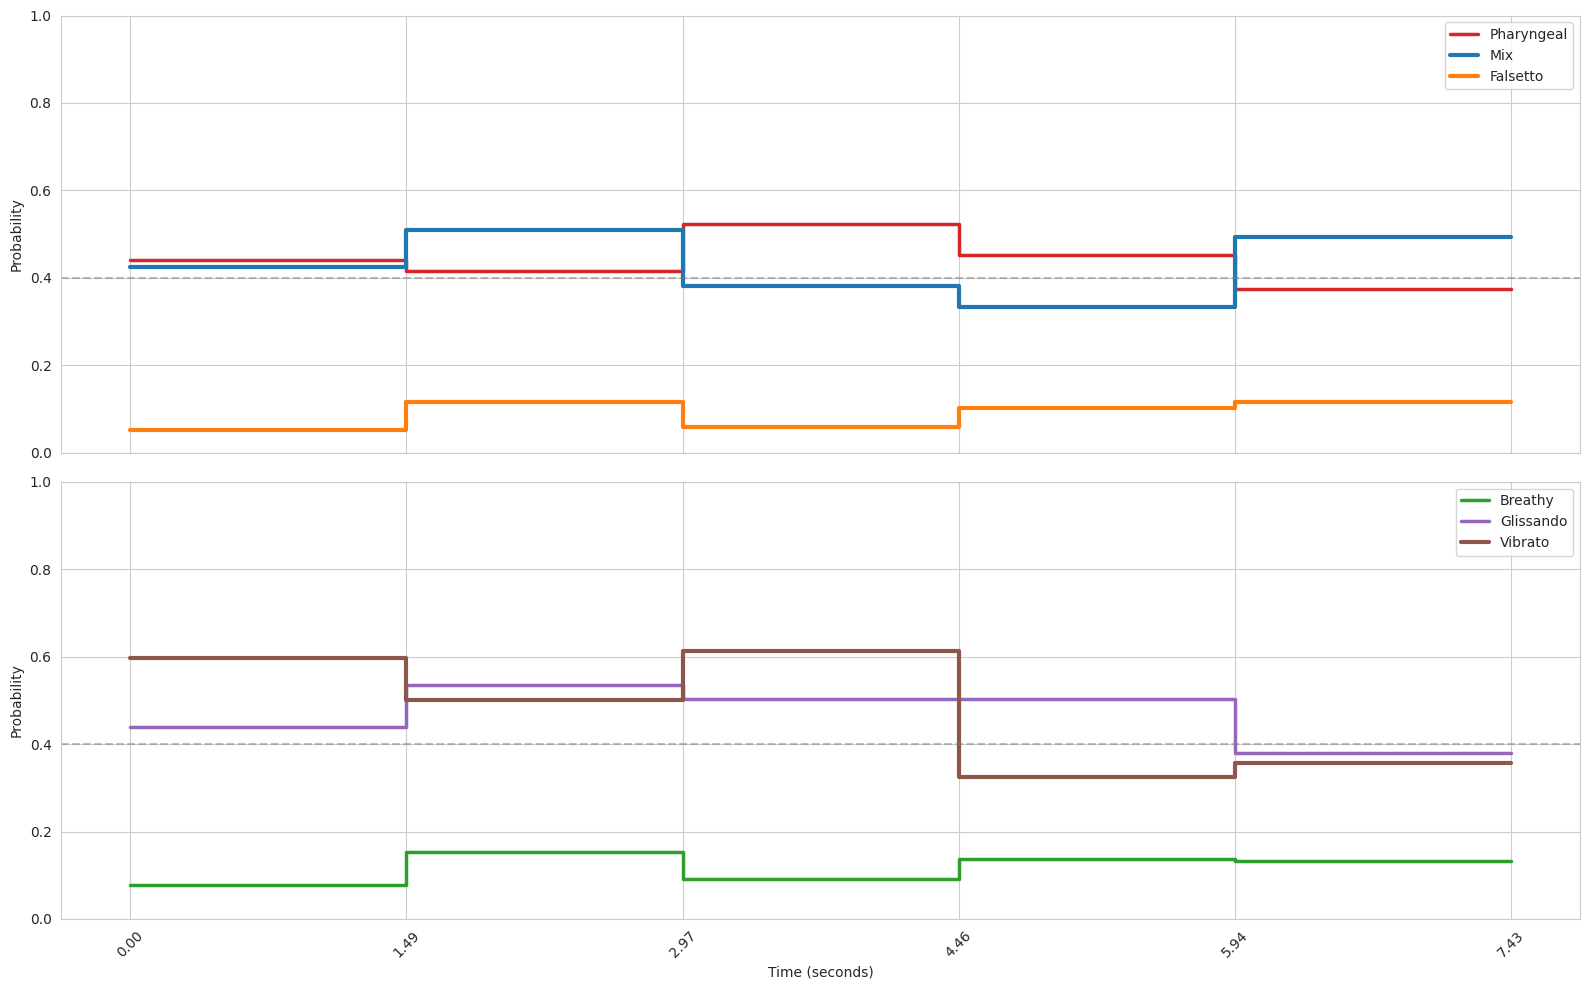

In [ ]:
final_df = analyze_vocal_track(X_m, X_p, times, model)

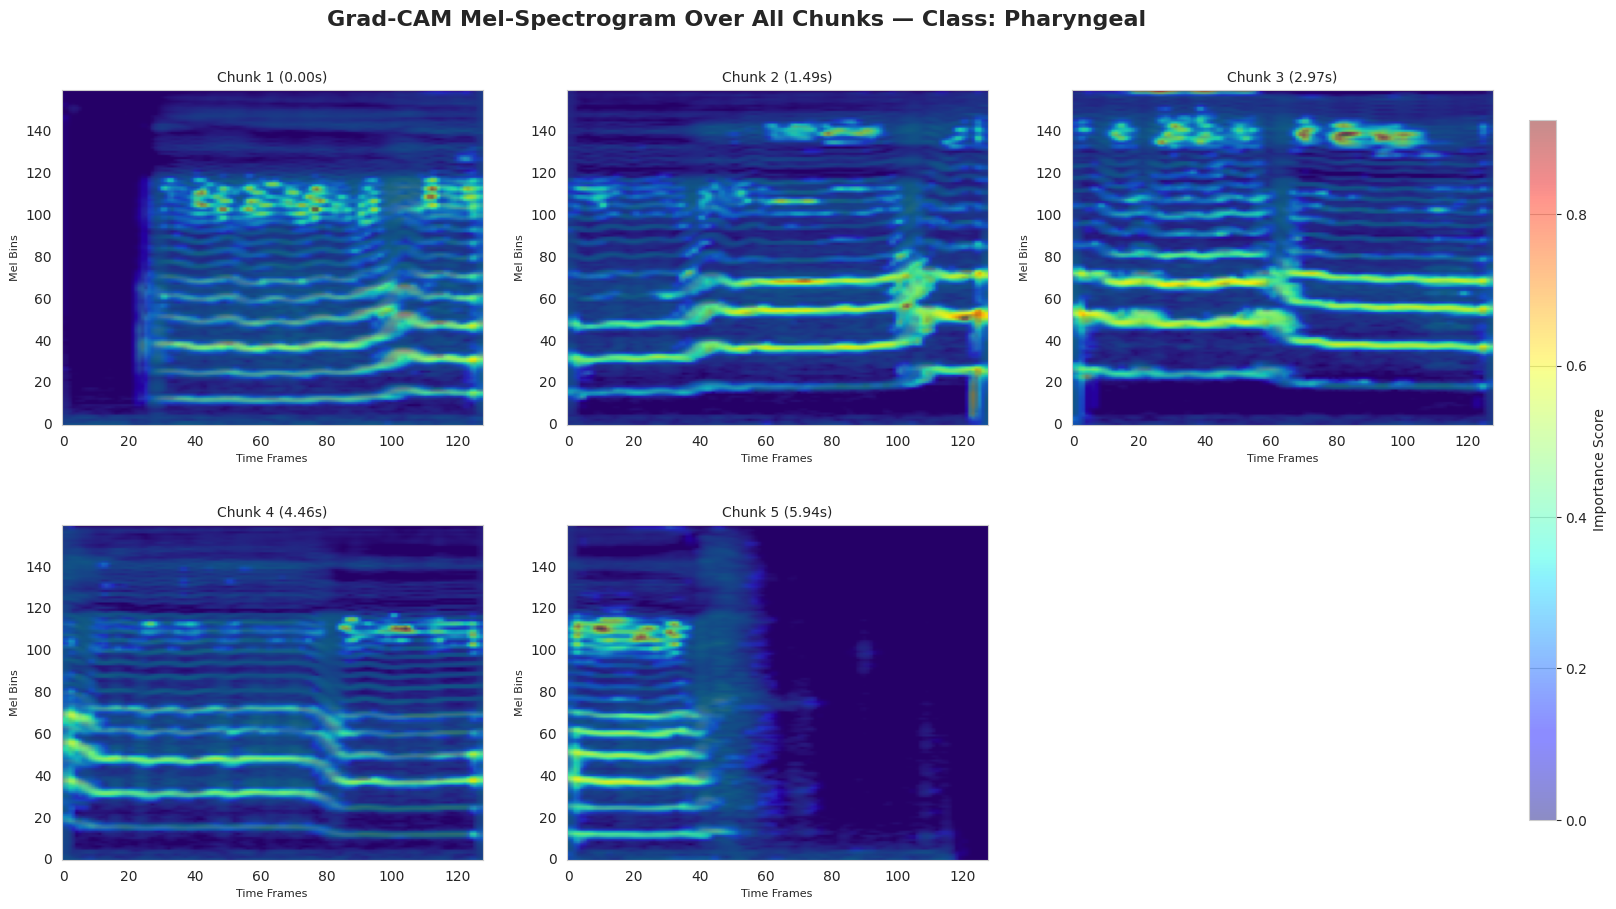

In [ ]:
plot_gradcam_grid(model, X_m, X_p, times, 3, 'Pharyngeal', layer_name='conv2d_7', max_chunks=6)

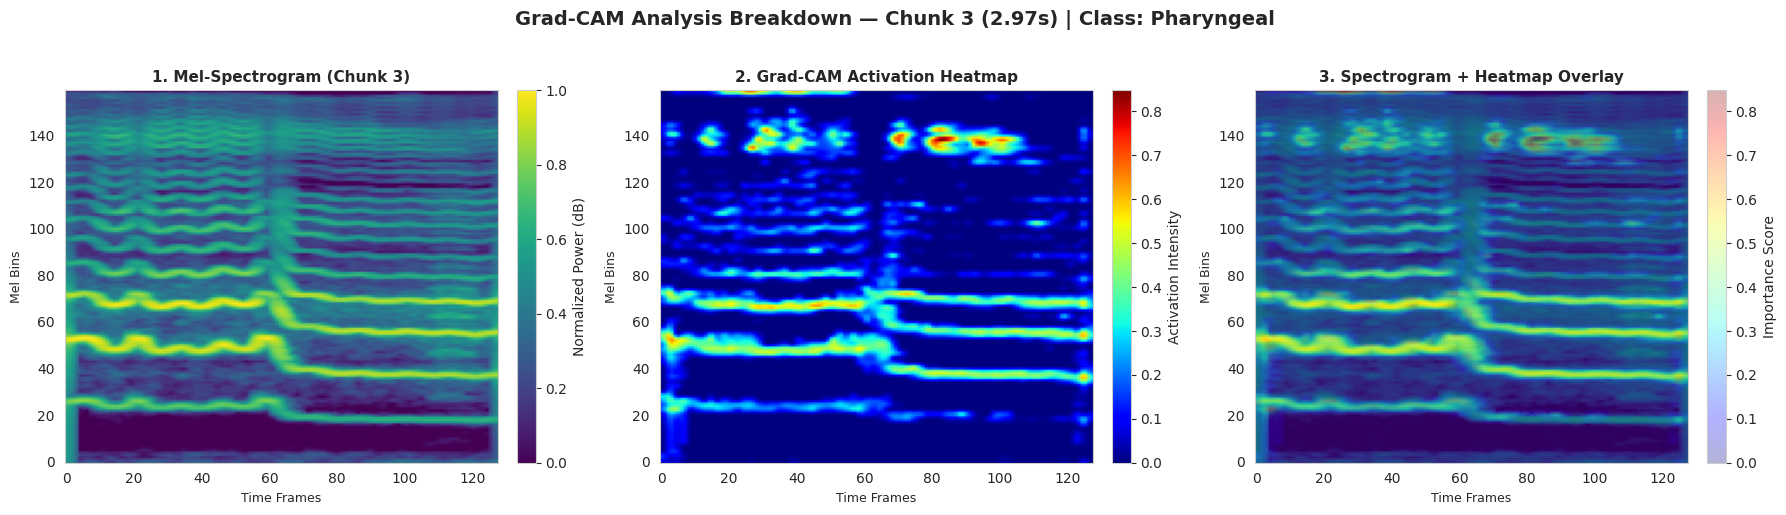

In [ ]:
plot_gradcam_breakdown(model, X_m, X_p, times, 2, 3, class_label="Pharyngeal")

### Vibrato Sample

In [ ]:
X_m, X_p, times = extract_audio_chunks('f1_arpeggios_vibrato_a.wav')

--- Running Model Prediction ---


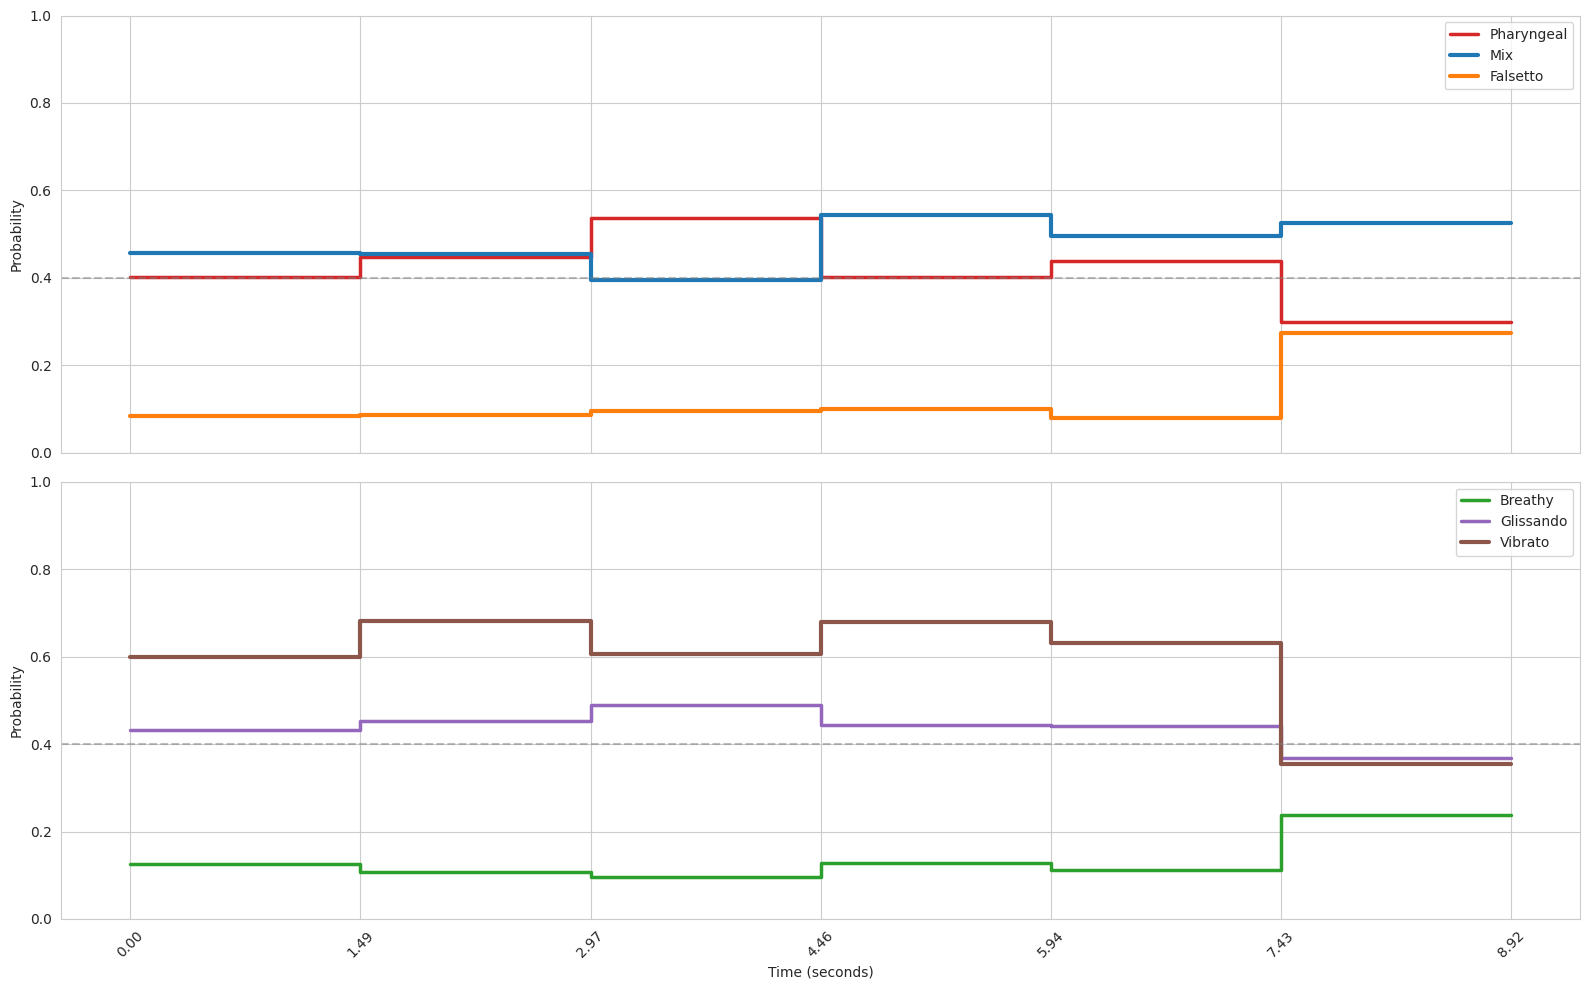

In [ ]:
final_df = analyze_vocal_track(X_m, X_p, times, model)

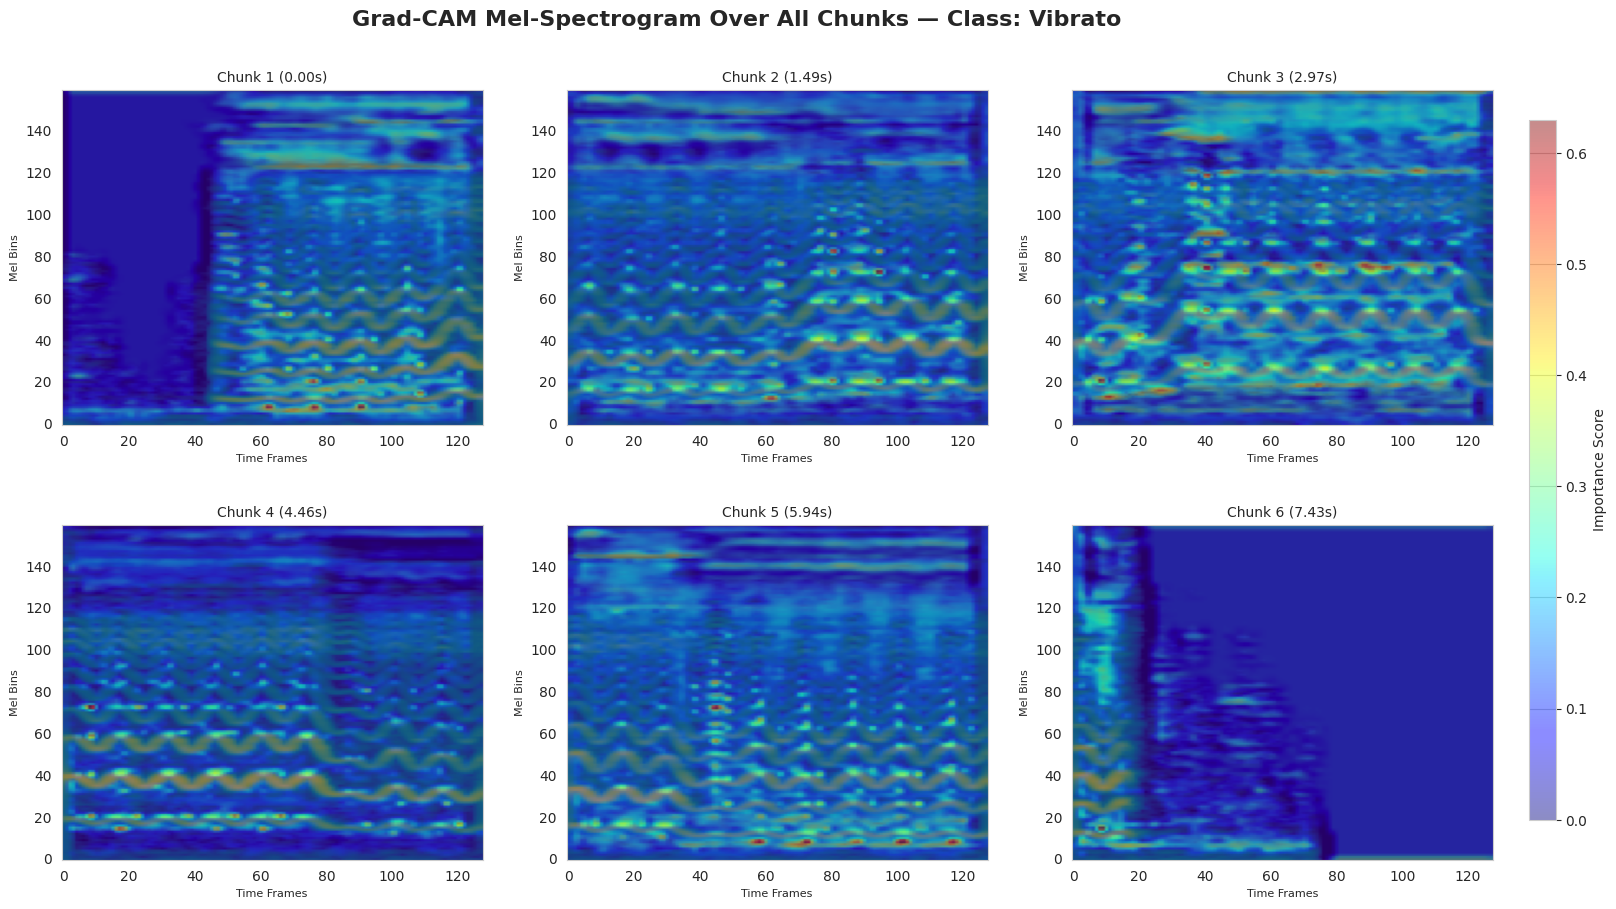

In [ ]:
plot_gradcam_grid(model, X_m, X_p, times, 5, 'Vibrato', layer_name='conv2d_7', max_chunks=6)

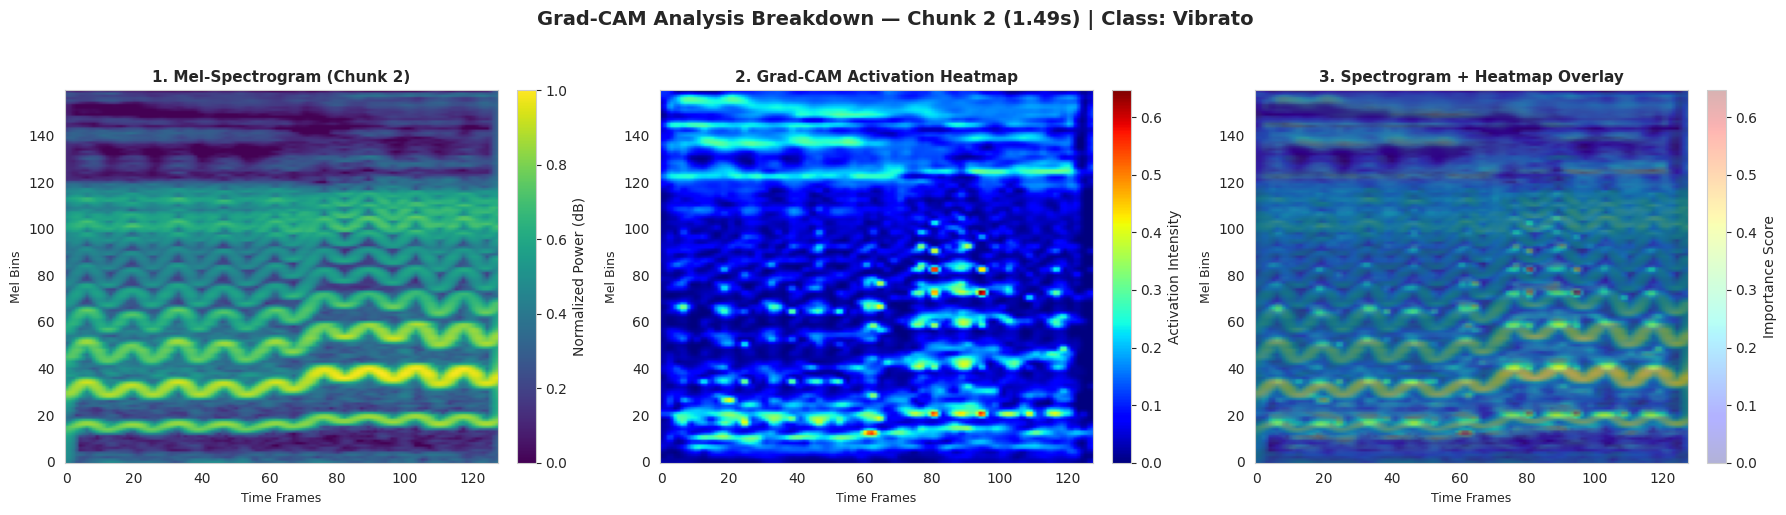

In [ ]:
plot_gradcam_breakdown(model, X_m, X_p, times, 1, 5, class_label="Vibrato")

## Emotion inference on VocalSet

In [ ]:
load_path = '/content/drive/MyDrive/ravdess_speech_opt_model.pkl'
package = joblib.load(load_path)

model_sp = package['model']
expected_features_sp = package['feature_names']
class_names = package['class_names']

print("Model loaded successfully!")
print(f"Expected features: {len(expected_features_sp)}: {expected_features_sp}")

Model loaded successfully!
Expected features: 19: ['loudness_sma3_percentile80.0', 'loudnessPeaksPerSec', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_amean', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'shimmerLocaldB_sma3nz_amean', 'shimmerLocaldB_sma3nz_stddevNorm', 'MeanVoicedSegmentLengthSec', 'HNRdBACF_sma3nz_amean', 'alphaRatioV_sma3nz_stddevNorm', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'alphaRatioV_sma3nz_amean', 'spectralFluxUV_sma3nz_amean', 'F1bandwidth_sma3nz_stddevNorm', 'logRelF0-H1-A3_sma3nz_amean', 'slopeV0-500_sma3nz_amean', 'F2frequency_sma3nz_stddevNorm', 'articulation_rate', 'std_phoneme_duration']


In [ ]:
load_path = '/content/drive/MyDrive/ravdess_singing_opt_model.pkl'
package = joblib.load(load_path)

model_si = package['model']
expected_features_si = package['feature_names']
class_names = package['class_names']

print("Model loaded successfully!")
print(f"Expected features: {len(expected_features_si)}: {expected_features_si}")

Model loaded successfully!
Expected features: 18: ['shimmerLocaldB_sma3nz_amean', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'loudnessPeaksPerSec', 'melodic_deviation', 'HNRdBACF_sma3nz_amean', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'alphaRatioV_sma3nz_stddevNorm', 'spectralFlux_sma3_amean', 'alphaRatioV_sma3nz_amean', 'articulation_rate', 'std_phoneme_duration', 'MFDR_vibrato', 'breathy_mean', 'pharyngeal_max', 'falsetto_max', 'glissando_max', 'tech_entropy']


### Using speech-optimized RAVDESS model

In [ ]:
# Inference for speech-opt
X_input = df_vocalset[expected_features_sp].values
y_pred_indices = model_sp.predict(X_input)
y_probs = model_sp.predict_proba(X_input)

df_vocalset['predicted_emotion'] = [class_names[i] for i in y_pred_indices]
df_vocalset['prediction_confidence'] = np.max(y_probs, axis=1)

print("Predictions made!")
df_vocalset['predicted_emotion'].value_counts()

Predictions made!


,count
predicted_emotion,
Sad,759
Happy,707
Fearful,415
Angry,386
Calm,266
Neutral,20


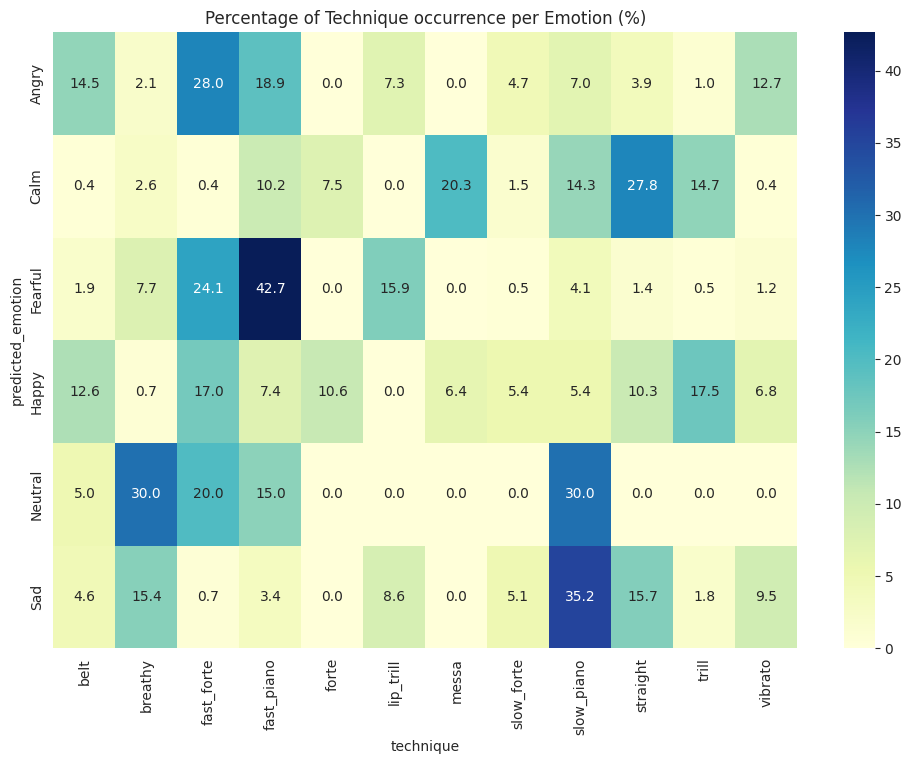

In [ ]:
# Calculate percentage distribution per sentiment for speech
ct_normalized = pd.crosstab(df_vocalset['predicted_emotion'], df_vocalset['technique'], normalize='index') * 100

plt.figure(figsize=(12, 8))
sns.heatmap(ct_normalized, annot=True, cmap="YlGnBu", fmt=".1f")
plt.title("Percentage of Technique occurrence per Emotion (%)")
plt.show()

In [ ]:
# Encode and Calculate Global Scores
df_vocalset['emotion_encoded'] = df_vocalset['predicted_emotion'].astype('category').cat.codes
df_vocalset['tech_encoded'] = df_vocalset['technique'].astype('category').cat.codes

mi = mutual_info_score(df_vocalset['emotion_encoded'], df_vocalset['tech_encoded'])
nmi = normalized_mutual_info_score(df_vocalset['emotion_encoded'], df_vocalset['tech_encoded'])

# Vectorized Analysis per Emotion
# Calculate MI and Entropy
summary_df = df_vocalset.groupby('predicted_emotion').apply(lambda x: pd.Series({
    'MI': mutual_info_score((df_vocalset['predicted_emotion'] == x.name).astype(int), df_vocalset['tech_encoded']),
    'Entropy': entropy(x['technique'].value_counts()) / (entropy([1] * len(x['technique'].unique())) if len(x['technique'].unique()) > 1 else 1)
})).reset_index()

print(f"Total MI: {mi:.4f} | NMI: {nmi:.4f}\n")
print(summary_df)

Total MI: 0.4281 | NMI: 0.2170

  predicted_emotion        MI   Entropy
0             Angry  0.055753  0.862787
1              Calm  0.074973  0.787232
2           Fearful  0.122521  0.681527
3             Happy  0.115408  0.933660
4           Neutral  0.005651  0.918722
5               Sad  0.175602  0.823802


/tmp/ipykernel_8556/1618738609.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary_df = df_vocalset.groupby('predicted_emotion').apply(lambda x: pd.Series({


### Using singing-optimized RAVDESS model

In [ ]:
# Inference for singing-opt
X_input = df_vocalset[expected_features_si].values
y_pred_indices = model_si.predict(X_input)
y_probs = model_si.predict_proba(X_input)

df_vocalset['predicted_emotion'] = [class_names[i] for i in y_pred_indices]
df_vocalset['prediction_confidence'] = np.max(y_probs, axis=1)

print("Predictions made!")
df_vocalset['predicted_emotion'].value_counts()

Predictions made!


,count
predicted_emotion,
Happy,769
Sad,664
Angry,440
Calm,326
Fearful,295
Neutral,59


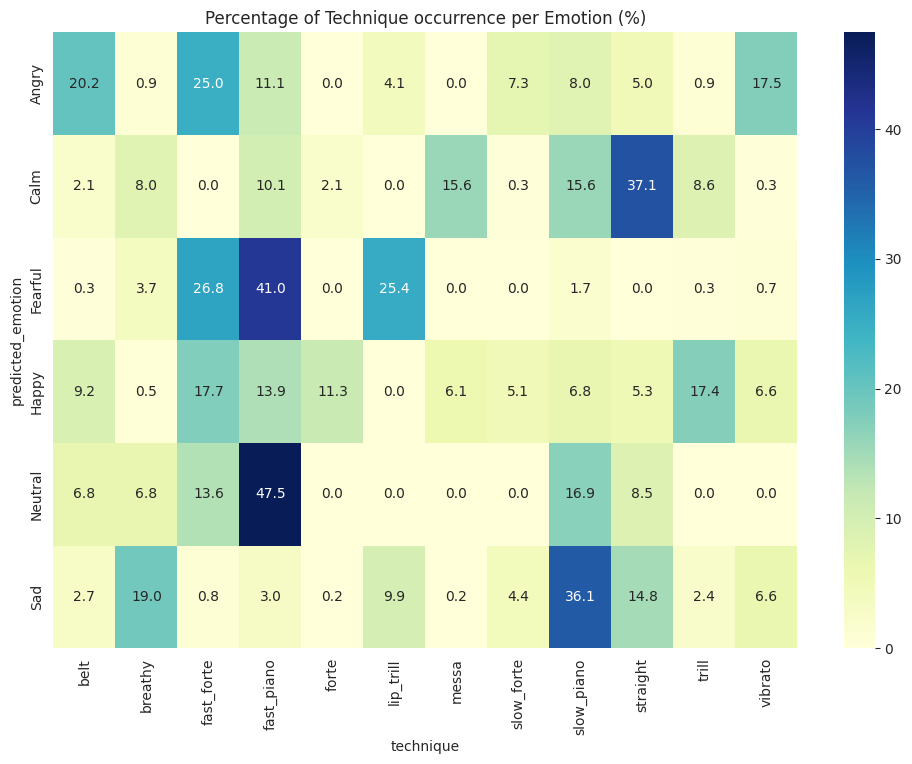

In [ ]:
ct_normalized = pd.crosstab(df_vocalset['predicted_emotion'], df_vocalset['technique'], normalize='index') * 100

plt.figure(figsize=(12, 8))
sns.heatmap(ct_normalized, annot=True, cmap="YlGnBu", fmt=".1f")
plt.title("Percentage of Technique occurrence per Emotion (%)")
plt.show()

In [ ]:
df_vocalset['emotion_encoded'] = df_vocalset['predicted_emotion'].astype('category').cat.codes
df_vocalset['tech_encoded'] = df_vocalset['technique'].astype('category').cat.codes

mi = mutual_info_score(df_vocalset['emotion_encoded'], df_vocalset['tech_encoded'])
nmi = normalized_mutual_info_score(df_vocalset['emotion_encoded'], df_vocalset['tech_encoded'])

# Vectorized Analysis per Emotion
# Calculate MI and Entropy
summary_df = df_vocalset.groupby('predicted_emotion').apply(lambda x: pd.Series({
    'MI': mutual_info_score((df_vocalset['predicted_emotion'] == x.name).astype(int), df_vocalset['tech_encoded']),
    'Entropy': entropy(x['technique'].value_counts()) / (entropy([1] * len(x['technique'].unique())) if len(x['technique'].unique()) > 1 else 1)
})).reset_index()

print(f"Total MI: {mi:.4f} | NMI: {nmi:.4f}\n")
print(summary_df)

Total MI: 0.4650 | NMI: 0.2331

  predicted_emotion        MI   Entropy
0             Angry  0.083264  0.858725
1              Calm  0.090426  0.778735
2           Fearful  0.117461  0.639935
3             Happy  0.127246  0.925628
4           Neutral  0.013417  0.836921
5               Sad  0.163446  0.748970


/tmp/ipykernel_8556/2382215030.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary_df = df_vocalset.groupby('predicted_emotion').apply(lambda x: pd.Series({


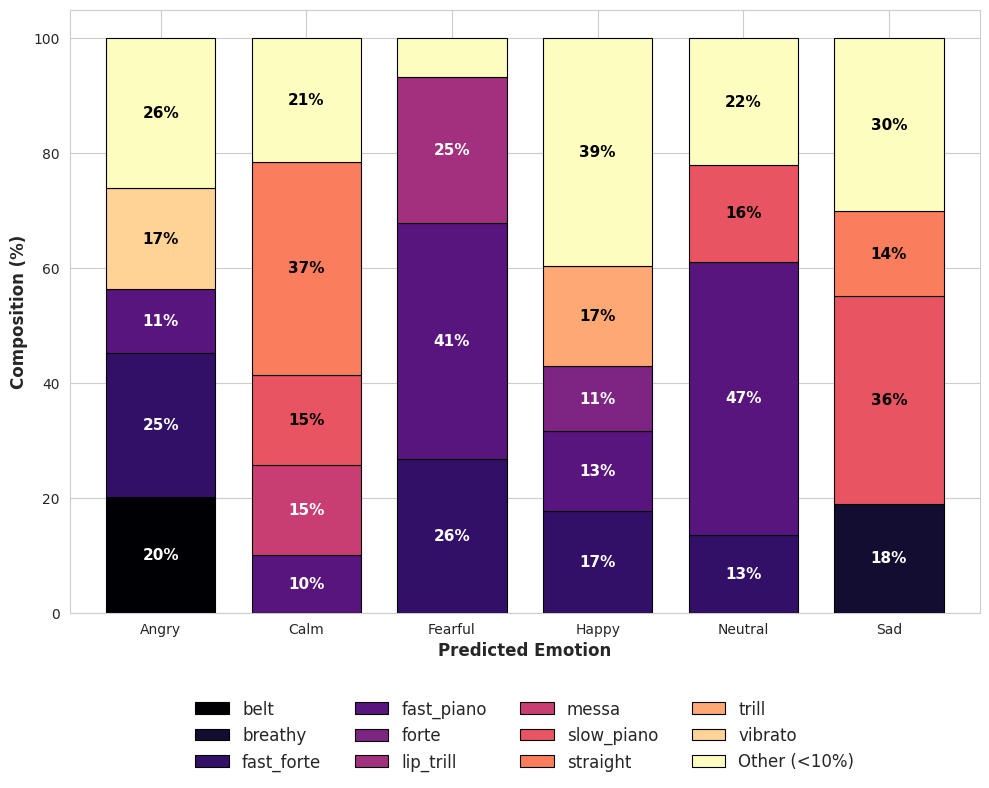

In [ ]:
ct = pd.crosstab(df_vocalset['predicted_emotion'], df_vocalset['technique'], normalize='index') * 100

def group_small_slices(row, threshold=10):
    small_slices = row[row < threshold]
    # Descriptive name for the category
    row['Other (<10%)'] = small_slices.sum()
    row[small_slices.index] = 0
    return row

ct_clean = ct.apply(group_small_slices, axis=1)

# Remove original columns that were zeroed out
ct_clean = ct_clean.loc[:, (ct_clean != 0).any(axis=0)]

# Reorder columns so "Other" is always at the end (top of stack)
cols = [c for c in ct_clean.columns if c != 'Other (<10%)'] + ['Other (<10%)']
ct_clean = ct_clean[cols]

fig, ax = plt.subplots(figsize=(10, 8))

ct_clean.plot(kind='bar',
              stacked=True,
              ax=ax,
              colormap='magma',
              edgecolor='black',
              linewidth=0.8,
              width=0.75)

# Smart labels (only big chunks)
for p in ax.patches:
    h = p.get_height()
    if h > 8:
        # Determine brightness of facecolor to toggle text color
        color_rgb = p.get_facecolor()
        brightness = (color_rgb[0] * 299 + color_rgb[1] * 587 + color_rgb[2] * 114) / 1000
        text_color = "white" if brightness < 0.5 else "black"

        ax.text(p.get_x() + p.get_width()/2.,
                p.get_y() + h/2.,
                f'{int(h)}%',
                ha='center', va='center',
                color=text_color, fontweight='bold', fontsize=11)

# Adjust Legend
ax.legend(
          loc='upper center',
          bbox_to_anchor=(0.5, -0.12),
          ncol=4,
          fontsize=12,
          frameon=False)

plt.ylabel('Composition (%)', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Emotion', fontsize=12, fontweight='bold')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/tmp/ipykernel_8556/3135062887.py:26: UserWarning: 
The palette list has fewer values (4) than needed (5) and will cycle, which may produce an uninterpretable plot.
  sns.scatterplot(


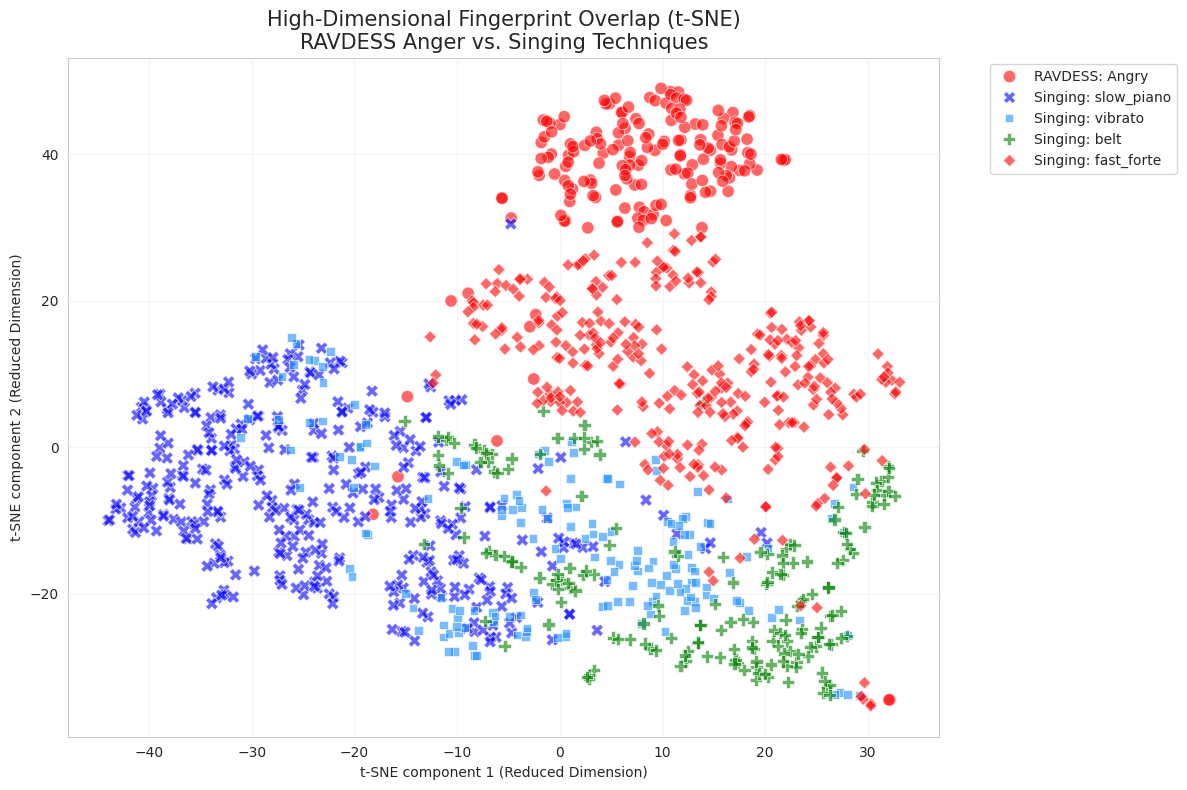

In [ ]:
from sklearn.manifold import TSNE

df_angry = df_ravdess[df_ravdess['emotion'] == 5][expected_features_si].copy()
df_angry['Label'] = 'RAVDESS: Angry'

techniques_to_compare = ['belt', 'vibrato', 'slow_piano', 'fast_forte']
df_vocal = df_vocalset[df_vocalset['technique'].isin(techniques_to_compare)].copy()

df_vocal_subset = df_vocal[expected_features_si].copy()
df_vocal_subset['Label'] = 'Singing: ' + df_vocal['technique']

combined_df = pd.concat([df_angry, df_vocal_subset], axis=0)
combined_df = combined_df.dropna(subset=expected_features_si)

features_only = combined_df[expected_features_si]

# t-SNE
tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, random_state=42)
tsne_results = tsne.fit_transform(features_only)

combined_df['tsne-1'] = tsne_results[:,0]
combined_df['tsne-2'] = tsne_results[:,1]

# Scatter Plot
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x='tsne-1', y='tsne-2',
    hue='Label',
    style='Label',
    data=combined_df,
    palette=['red', 'blue', 'dodgerblue', 'green'],
    alpha=0.6,
    s=80
)

plt.title('High-Dimensional Fingerprint Overlap (t-SNE)\nRAVDESS Anger vs. Singing Techniques', fontsize=15)
plt.xlabel('t-SNE component 1 (Reduced Dimension)')
plt.ylabel('t-SNE component 2 (Reduced Dimension)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

# GTSinger

In [ ]:
df_gtsinger = pd.read_csv('df_gtsinger_check(3).csv')

In [ ]:
df_gtsinger.shape

(10656, 161)

In [ ]:
df_gtsinger.language.value_counts()

,count
language,
EN,4721
DE,3397
FR,2538


In [ ]:
df_gtsinger.emotion.value_counts()

,count
emotion,
happy,5513
sad,5143


In [ ]:
unique_performances = df_gtsinger.groupby('emotion')['performance_folder'].nunique()

print("Song Count per Emotion:")
print(unique_performances)

print(f"\nTotal perfomances: {unique_performances.sum()}")

Song Count per Emotion:
emotion
happy    634
sad      594
Name: performance_folder, dtype: int64

Total perfomances: 1228


In [ ]:
crosstab_result = pd.crosstab(df_gtsinger['unique_singer_id'], df_gtsinger['singing_method'])

print(crosstab_result)

singing_method    bel canto   pop
unique_singer_id                 
DE-Soprano-1           1724     0
DE-Tenor-1             1673     0
EN-Alto-1                 0  1252
EN-Alto-2                 0  1703
EN-Tenor-1                0  1766
FR-Soprano-1              0  1223
FR-Tenor-1             1315     0


In [ ]:
crosstab_result = pd.crosstab(df_gtsinger['unique_singer_id'], df_gtsinger['emotion'])

print(crosstab_result)

emotion           happy   sad
unique_singer_id             
DE-Soprano-1        666  1058
DE-Tenor-1         1143   530
EN-Alto-1           525   727
EN-Alto-2           579  1124
EN-Tenor-1          710  1056
FR-Soprano-1        900   323
FR-Tenor-1          990   325


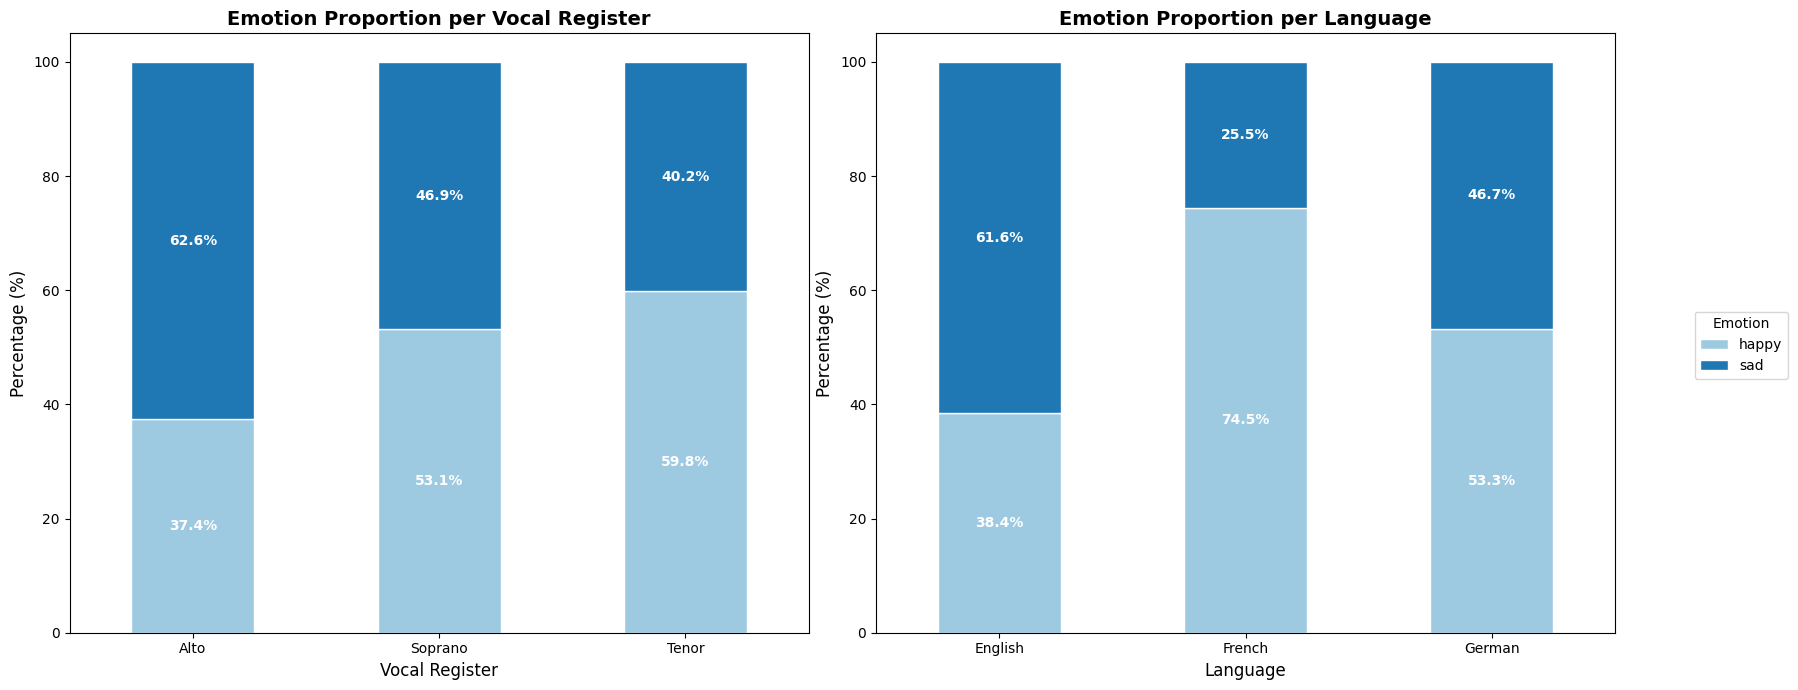

In [ ]:
df_gtsinger['vocal_register_clean'] = df_gtsinger['range_folder'].str.split('-').str[0]

lang_map = {'EN': 'English', 'FR': 'French', 'DE': 'German'}
df_gtsinger['language_clean'] = df_gtsinger['language'].map(lang_map)


ct_register = pd.crosstab(df_gtsinger['vocal_register_clean'], df_gtsinger['emotion'], normalize='index') * 100
ct_language = pd.crosstab(df_gtsinger['language_clean'], df_gtsinger['emotion'], normalize='index') * 100


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
colors = ['#9ecae1', '#1f77b4']

# --- Subplot 1: Vocal register ---
ct_register.plot(kind='bar', stacked=True, ax=ax1, color=colors, edgecolor='white')
ax1.set_title('Emotion Proportion per Vocal Register', fontsize=14, fontweight='bold')
ax1.set_ylabel('Percentage (%)', fontsize=12)
ax1.set_xlabel('Vocal Register', fontsize=12)
ax1.tick_params(axis='x', rotation=0)

# --- Subplot 2: Language ---
ct_language.plot(kind='bar', stacked=True, ax=ax2, color=colors, edgecolor='white')
ax2.set_title('Emotion Proportion per Language', fontsize=14, fontweight='bold')
ax2.set_ylabel('Percentage (%)', fontsize=12)
ax2.set_xlabel('Language', fontsize=12)
ax2.tick_params(axis='x', rotation=0)

for ax in [ax1, ax2]:
    for p in ax.patches:
        width, height = p.get_width(), p.get_height()
        x, y = p.get_xy()
        if height > 0:
            ax.text(x + width/2, y + height/2, f'{height:.1f}%',
                    ha='center', va='center', fontsize=10,
                    fontweight='bold', color='white' if height > 15 else 'black')

ax1.get_legend().remove()
ax2.get_legend().remove()
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, title='Emotion', loc='center right', bbox_to_anchor=(1.0, 0.5))

plt.tight_layout()
plt.subplots_adjust(right=0.9)

plt.show()

In [ ]:
load_path = '/content/drive/MyDrive/ravdess_singing_opt_model.pkl'
package = joblib.load(load_path)

model_si = package['model']
expected_features_si = package['feature_names']
class_names = package['class_names']

print("Model loaded successfully!")
print(f"Expected features: {len(expected_features_si)}: {expected_features_si}")

Model loaded successfully!
Expected features: 18: ['shimmerLocaldB_sma3nz_amean', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'loudnessPeaksPerSec', 'melodic_deviation', 'HNRdBACF_sma3nz_amean', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'alphaRatioV_sma3nz_stddevNorm', 'spectralFlux_sma3_amean', 'alphaRatioV_sma3nz_amean', 'articulation_rate', 'std_phoneme_duration', 'MFDR_vibrato', 'breathy_mean', 'pharyngeal_max', 'falsetto_max', 'glissando_max', 'tech_entropy']


In [ ]:
load_path = '/content/drive/MyDrive/ravdess_speech_opt_model.pkl'
package = joblib.load(load_path)

model_sp = package['model']
expected_features_sp = package['feature_names']
class_names = package['class_names']

print("Model loaded successfully!")
print(f"Expected features: {len(expected_features_sp)}: {expected_features_sp}")

Model loaded successfully!
Expected features: 19: ['loudness_sma3_percentile80.0', 'loudnessPeaksPerSec', 'F0semitoneFrom27.5Hz_sma3nz_stddevNorm', 'F0semitoneFrom27.5Hz_sma3nz_amean', 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'shimmerLocaldB_sma3nz_amean', 'shimmerLocaldB_sma3nz_stddevNorm', 'MeanVoicedSegmentLengthSec', 'HNRdBACF_sma3nz_amean', 'alphaRatioV_sma3nz_stddevNorm', 'F2amplitudeLogRelF0_sma3nz_stddevNorm', 'alphaRatioV_sma3nz_amean', 'spectralFluxUV_sma3nz_amean', 'F1bandwidth_sma3nz_stddevNorm', 'logRelF0-H1-A3_sma3nz_amean', 'slopeV0-500_sma3nz_amean', 'F2frequency_sma3nz_stddevNorm', 'articulation_rate', 'std_phoneme_duration']


In [ ]:
def perform_loso_cross_validation(df, features_col, target_col, singer_id_col, wav_path_col):
    # Group by perfomance folder
    df['performance_folder'] = df[wav_path_col].apply(lambda x: os.path.dirname(x))

    X = df[features_col].values

    y = df[target_col].values
    groups = df[singer_id_col].values
    performance_ids = df['performance_folder'].values

    n_speakers = len(np.unique(groups))
    gkf = GroupKFold(n_splits=n_speakers)

    perf_accuracies = []
    all_final_preds = []
    all_final_actuals = []
    all_final_styles = []
    fold_balanced_accs = []
    fold_f1_scores = []

    print(f"LOSO Cross-Validation for {n_speakers} singer...")
    print(f"Calculating Majority Vote per Performance Folder...\n")

    fold = 1
    for train_idx, test_idx in gkf.split(X, y, groups=groups):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        test_performances = performance_ids[test_idx]

        model = RandomForestClassifier(
          n_estimators=200,
          max_depth=12,         # Higher depth
          min_samples_leaf=10,
          class_weight='balanced',
          random_state=42
      )
        model.fit(X_train, y_train)

        y_pred_segments = model.predict(X_test)

        unique_performances = np.unique(test_performances)
        correct_count = 0
        perf_preds_list = []
        perf_actuals_list = []

        for perf in unique_performances:
            idx = np.where(test_performances == perf)[0]
            perf_preds = y_pred_segments[idx]
            perf_actual = y_test[idx][0]
            style = df[df['performance_folder'] == perf]['singing_method'].iloc[0]

            # Majority Vote
            vals, counts = np.unique(perf_preds, return_counts=True)
            majority_val = vals[np.argmax(counts)]

            perf_preds_list.append(majority_val)
            perf_actuals_list.append(perf_actual)

            all_final_preds.append(majority_val)
            all_final_actuals.append(perf_actual)
            all_final_styles.append(style) # Save perfomance style

            if majority_val == perf_actual:
                correct_count += 1

        fold_acc = (correct_count / len(unique_performances)) * 100
        perf_accuracies.append(fold_acc)

        f_bacc = balanced_accuracy_score(perf_actuals_list, perf_preds_list)
        f_f1 = f1_score(perf_actuals_list, perf_preds_list, average='macro')

        fold_balanced_accs.append(f_bacc * 100)
        fold_f1_scores.append(f_f1)

        current_singer = np.unique(groups[test_idx])[0]
        print(f"Fold {fold} | Speaker: {current_singer} | Balanced Acc: {f_bacc*100:.2f}% | F1: {f_f1:.2f}")
        fold += 1

    print("\n" + "="*60)
    print(f"FINAL LOSO RESULTS (Majority Vote)")

    mean_bacc = np.mean(fold_balanced_accs)
    std_bacc = np.std(fold_balanced_accs)
    mean_f1 = np.mean(fold_f1_scores)

    print(f"Mean Balanced Accuracy (Per Speaker): {mean_bacc:.2f}%")
    print(f"Inter-Speaker Stability (STD): {std_bacc:.2f}%")
    print(f"Mean F1-score: {mean_f1:.2f}")
    print("="*60)

    # Global Balanced Accuracy
    global_balanced_acc = balanced_accuracy_score(all_final_actuals, all_final_preds)

    return {
        "accuracies": perf_accuracies,
        "y_pred": all_final_preds,
        "y_true": all_final_actuals,
        "mean_acc": np.mean(perf_accuracies),
        "std_acc": np.std(perf_accuracies),
        'style': all_final_styles
    }

In [ ]:
results_speech = perform_loso_cross_validation(df_gtsinger, expected_features_sp, 'emotion', 'unique_singer_id', 'wav_path')

LOSO Cross-Validation for 7 singer...
Calculating Majority Vote per Performance Folder...

Fold 1 | Speaker: EN-Tenor-1 | Balanced Acc: 60.63% | F1: 0.60
Fold 2 | Speaker: DE-Soprano-1 | Balanced Acc: 71.23% | F1: 0.70
Fold 3 | Speaker: EN-Alto-2 | Balanced Acc: 61.87% | F1: 0.61
Fold 4 | Speaker: DE-Tenor-1 | Balanced Acc: 62.32% | F1: 0.63
Fold 5 | Speaker: FR-Tenor-1 | Balanced Acc: 72.16% | F1: 0.71
Fold 6 | Speaker: EN-Alto-1 | Balanced Acc: 62.68% | F1: 0.61
Fold 7 | Speaker: FR-Soprano-1 | Balanced Acc: 52.35% | F1: 0.52

FINAL LOSO RESULTS (Majority Vote)
Mean Balanced Accuracy (Per Speaker): 63.32%
Inter-Speaker Stability (STD): 6.23%
Mean F1-score: 0.63


In [ ]:
results_ravdess = perform_loso_cross_validation(df_gtsinger, expected_features_si, 'emotion', 'unique_singer_id', 'wav_path')

LOSO Cross-Validation for 7 singer...
Calculating Majority Vote per Performance Folder...

Fold 1 | Speaker: EN-Tenor-1 | Balanced Acc: 61.96% | F1: 0.61
Fold 2 | Speaker: DE-Soprano-1 | Balanced Acc: 60.38% | F1: 0.58
Fold 3 | Speaker: EN-Alto-2 | Balanced Acc: 58.96% | F1: 0.59
Fold 4 | Speaker: DE-Tenor-1 | Balanced Acc: 60.90% | F1: 0.55
Fold 5 | Speaker: FR-Tenor-1 | Balanced Acc: 55.43% | F1: 0.56
Fold 6 | Speaker: EN-Alto-1 | Balanced Acc: 59.35% | F1: 0.48
Fold 7 | Speaker: FR-Soprano-1 | Balanced Acc: 59.04% | F1: 0.53

FINAL LOSO RESULTS (Majority Vote)
Mean Balanced Accuracy (Per Speaker): 59.43%
Inter-Speaker Stability (STD): 1.92%
Mean F1-score: 0.56


## Feature Selection

In [ ]:
def perform_nested_loso_rf(df, categories_list, target_col, singer_id_col, wav_path_col, total_top_k=20):
    df = df.copy()

    df['performance_folder'] = df[wav_path_col].apply(lambda x: os.path.dirname(x))

    # Flatten all feature categories into a single list
    all_features = [f for sublist in categories_list.values() for f in sublist]
    groups = df[singer_id_col]
    y = df[target_col].values

    logo_outer = LeaveOneGroupOut()

    all_final_preds = []
    all_final_actuals = []
    selected_features_per_fold = []
    feature_importances_per_fold = []

    print(f"Starting Nested LOSO with Global Feature Selection ({groups.nunique()} singers)")

    # --- OUTER LOOP ---
    for fold, (train_idx, test_idx) in enumerate(logo_outer.split(df[all_features], y, groups), 1):
        df_train = df.iloc[train_idx].reset_index(drop=True)
        df_test = df.iloc[test_idx].reset_index(drop=True)

        test_singer = df_test[singer_id_col].iloc[0]
        print(f"\nFold {fold}: Testing on Singer {test_singer}")

        # --- INNER LOOP: Feature Selection ---
        print(f"   --- Running Inner Feature Selection (Stability Check)...")
        inner_feature_counter = Counter()
        logo_inner = LeaveOneGroupOut()

        inner_groups = df_train[singer_id_col].values
        inner_y = df_train[target_col].values
        X_inner_all = df_train[all_features]

        inner_importance_sum = defaultdict(float)

        for i_train_idx, i_val_idx in logo_inner.split(X_inner_all, inner_y, inner_groups):
            X_i_train, y_i_train = X_inner_all.iloc[i_train_idx], inner_y[i_train_idx]

            # Shallow Random Forest for feature importance estimation
            rf_inner = RandomForestClassifier(n_estimators=50, max_depth=6, random_state=42, class_weight='balanced')
            rf_inner.fit(X_i_train, y_i_train)

            # Feature Importance DataFrame
            inner_importance = pd.DataFrame({'feat': all_features, 'imp': rf_inner.feature_importances_})

            # Select top K features in each inner fold
            top_k_inner = inner_importance.sort_values(by='imp', ascending=False).head(total_top_k)
            inner_feature_counter.update(top_k_inner['feat'].tolist())

            fold_importances = dict(zip(all_features, rf_inner.feature_importances_))
            # Accumulate importances
            for feat, imp in fold_importances.items():
              inner_importance_sum[feat] += imp


        # Select the final top K features with the highest vote frequency across inner folds
        final_selected_features = [f for f, count in inner_feature_counter.most_common(total_top_k)]
        final_sel_feats_imps    = {feat: inner_importance_sum[feat] for feat in final_selected_features}

        selected_features_per_fold.append(final_selected_features)
        feature_importances_per_fold.append(final_sel_feats_imps)

        print(f"   --- Selected top {len(final_selected_features)} most stable features:")
        print(final_sel_feats_imps)


    return selected_features_per_fold, feature_importances_per_fold

In [ ]:
def get_feature_stability_ranking(selected_features_per_fold):
    """
    Accepts a list of dictionaries (containing selected features and their importances per fold)
    and calculates feature stability and importance statistics across all folds.
    """
    # Structures to store feature metrics
    feat_counts = defaultdict(int)
    feat_importances = defaultdict(list)

    total_folds = len(selected_features_per_fold)

    # 1. Aggregate fold data
    for fold_data in selected_features_per_fold:
        feats = list(fold_data.keys())

        for feat in feats:
            feat_counts[feat] += 1
            feat_importances[feat].append(fold_data[feat])

    # 2. Compute feature statistics
    ranking_data = []
    for feat in feat_counts:
        freq = feat_counts[feat]
        imps = feat_importances[feat]

        mean_imp = np.mean(imps)
        std_imp = np.std(imps) if len(imps) > 1 else 0

        ranking_data.append({
            'Feature': feat,
            'Frequency': freq,
            'Selection_Rate (%)': (freq / total_folds) * 100,
            'Mean_Importance': mean_imp,
            'Std_Importance': std_imp,
            # Stability Score: Selection Frequency * Mean Importance
            'Stability_Score': (freq / total_folds) * mean_imp,
            'CV': mean_imp / std_imp if std_imp > 0 else 0
        })

    # 3. Create DataFrame and sort by Stability Score
    df_ranking = pd.DataFrame(ranking_data)
    df_ranking = df_ranking.sort_values(by='Stability_Score', ascending=False).reset_index(drop=True)

    return df_ranking

In [ ]:
categories = {
    #'prosodic': prosodic,
    #'spectral': spectral,
    #'phonemes': phonemes,
    'techniques': techniques
}

In [ ]:
prosodic = perform_nested_loso_rf(df_gtsinger, categories, 'emotion', 'unique_singer_id', 'wav_path', 10)

Starting Nested LOSO with Global Feature Selection (7 singers)

Fold 1: Testing on Singer DE-Soprano-1
   --- Running Inner Feature Selection (Stability Check)...
   --- Selected top 10 most stable features:
{'F0semitoneFrom27.5Hz_sma3nz_stddevFallingSlope': np.float64(0.47155469774034103), 'F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope': np.float64(0.31627509808695753), 'F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope': np.float64(0.4326492156939725), 'F0semitoneFrom27.5Hz_sma3nz_percentile20.0': np.float64(0.2400767999108599), 'F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope': np.float64(0.2437622085424189), 'F0semitoneFrom27.5Hz_sma3nz_percentile50.0': np.float64(0.3285946587893477), 'loudnessPeaksPerSec': np.float64(0.2291548275697874), 'MeanVoicedSegmentLengthSec': np.float64(0.1822194682274975), 'F0semitoneFrom27.5Hz_sma3nz_percentile80.0': np.float64(0.19600790220556663), 'delta_energy_std': np.float64(0.14176746315733718)}

Fold 2: Testing on Singer DE-Tenor-1
   --- Running Inner Fea

In [ ]:
ranking_df = get_feature_stability_ranking(prosodic[1])
print(ranking_df)

                                           Feature  Frequency  \
0                              loudnessPeaksPerSec          7   
1                       MeanVoicedSegmentLengthSec          7   
2                      shimmerLocaldB_sma3nz_amean          6   
3      F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope          6   
4       F0semitoneFrom27.5Hz_sma3nz_percentile50.0          7   
5    F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope          6   
6       F0semitoneFrom27.5Hz_sma3nz_percentile20.0          7   
7                             VoicedSegmentsPerSec          6   
8                         jitterLocal_sma3nz_amean          5   
9     F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope          2   
10  F0semitoneFrom27.5Hz_sma3nz_stddevFallingSlope          2   
11        F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2          2   
12                         st_loudness_variability          2   
13                  loudness_sma3_meanFallingSlope          1   
14      F0semitoneFrom27.

In [ ]:
spectral = perform_nested_loso_rf(df_gtsinger, categories, 'emotion', 'unique_singer_id', 'wav_path', 10)

Starting Nested LOSO with Global Feature Selection (7 singers)

Fold 1: Testing on Singer DE-Soprano-1
   --- Running Inner Feature Selection (Stability Check)...
   --- Selected top 10 most stable features:
{'slopeV500-1500_sma3nz_stddevNorm': np.float64(0.5439738130135148), 'alphaRatioV_sma3nz_stddevNorm': np.float64(0.47964716995789386), 'slopeV0-500_sma3nz_stddevNorm': np.float64(0.24305947653307444), 'hammarbergIndexV_sma3nz_stddevNorm': np.float64(0.3444642705759852), 'logRelF0-H1-A3_sma3nz_stddevNorm': np.float64(0.3775091358519583), 'HNRdBACF_sma3nz_stddevNorm': np.float64(0.24427093958424284), 'spectralFluxV_sma3nz_amean': np.float64(0.22519899890200384), 'spectralFlux_sma3_amean': np.float64(0.16599802120737855), 'F3amplitudeLogRelF0_sma3nz_stddevNorm': np.float64(0.19224615107458853), 'spectralFluxUV_sma3nz_amean': np.float64(0.12358784554974916)}

Fold 2: Testing on Singer DE-Tenor-1
   --- Running Inner Feature Selection (Stability Check)...
   --- Selected top 10 most sta

In [ ]:
ranking_df = get_feature_stability_ranking(spectral[1])
print(ranking_df)

                                  Feature  Frequency  Selection_Rate (%)  \
0           alphaRatioV_sma3nz_stddevNorm          7          100.000000   
1        slopeV500-1500_sma3nz_stddevNorm          7          100.000000   
2              HNRdBACF_sma3nz_stddevNorm          7          100.000000   
3        logRelF0-H1-A3_sma3nz_stddevNorm          7          100.000000   
4      hammarbergIndexV_sma3nz_stddevNorm          7          100.000000   
5              spectralFluxV_sma3nz_amean          7          100.000000   
6   F3amplitudeLogRelF0_sma3nz_stddevNorm          7          100.000000   
7           slopeV0-500_sma3nz_stddevNorm          6           85.714286   
8   F1amplitudeLogRelF0_sma3nz_stddevNorm          5           71.428571   
9                 spectralFlux_sma3_amean          4           57.142857   
10                 spectral_flatness_mean          1           14.285714   
11       F1amplitudeLogRelF0_sma3nz_amean          1           14.285714   
12       F3a

In [ ]:
phonetic = perform_nested_loso_rf(df_gtsinger, categories, 'emotion', 'unique_singer_id', 'wav_path', 10)

Starting Nested LOSO with Global Feature Selection (7 singers)

Fold 1: Testing on Singer DE-Soprano-1
   --- Running Inner Feature Selection (Stability Check)...
   --- Selected top 9 most stable features:
{'mean_phoneme_duration': np.float64(1.1344120285859105), 'articulation_rate': np.float64(1.0326094112976127), 'std_phoneme_duration': np.float64(0.9052481115374291), 'std_pause_duration': np.float64(0.6983412054737638), 'phoneme_duration_cv': np.float64(0.5243852667547897), 'avg_distance_pauses': np.float64(0.49072537557606444), 'pause_ratio': np.float64(0.42028944219541425), 'vowel_ratio': np.float64(0.3793663974046577), 'mean_pause_duration': np.float64(0.41462276117435765)}

Fold 2: Testing on Singer DE-Tenor-1
   --- Running Inner Feature Selection (Stability Check)...
   --- Selected top 9 most stable features:
{'mean_phoneme_duration': np.float64(1.3296338640659207), 'articulation_rate': np.float64(1.5227539541639787), 'std_phoneme_duration': np.float64(0.7806462168295404), '

In [ ]:
ranking_df = get_feature_stability_ranking(phonetic[1])
print(ranking_df)

                 Feature  Frequency  Selection_Rate (%)  Mean_Importance  \
0      articulation_rate          7               100.0         1.368913   
1  mean_phoneme_duration          7               100.0         1.148961   
2   std_phoneme_duration          7               100.0         0.821497   
3     std_pause_duration          7               100.0         0.661616   
4    phoneme_duration_cv          7               100.0         0.476792   
5    avg_distance_pauses          7               100.0         0.413281   
6            pause_ratio          7               100.0         0.396318   
7            vowel_ratio          7               100.0         0.367707   
8    mean_pause_duration          7               100.0         0.344915   

   Std_Importance  Stability_Score         CV  
0        0.169191         1.368913   8.090910  
1        0.083286         1.148961  13.795408  
2        0.068990         0.821497  11.907531  
3        0.060128         0.661616  11.003404  

In [ ]:
technique = perform_nested_loso_rf(df_gtsinger, categories, 'emotion', 'unique_singer_id', 'wav_path', 10)

Starting Nested LOSO with Global Feature Selection (7 singers)

Fold 1: Testing on Singer DE-Soprano-1
   --- Running Inner Feature Selection (Stability Check)...
   --- Selected top 10 most stable features:
{'pharyngeal_std': np.float64(0.3565722946176412), 'pharyngeal_mean': np.float64(0.5343574548614205), 'vibrato_std': np.float64(0.2831941930649846), 'pharyngeal_max': np.float64(0.45035133452952053), 'glissando_mean': np.float64(0.2456286714550864), 'vibrato_peak_factor': np.float64(0.2719372833381044), 'vibrato_mean': np.float64(0.2734033935543461), 'MFDR_slow': np.float64(0.19429214682142962), 'breathy_mean': np.float64(0.19884224583642265), 'pharyngeal_peak_factor': np.float64(0.2253264417174609)}

Fold 2: Testing on Singer DE-Tenor-1
   --- Running Inner Feature Selection (Stability Check)...
   --- Selected top 10 most stable features:
{'MFDR_slow': np.float64(0.4351690575538926), 'falsetto_mean': np.float64(0.34362570699045314), 'falsetto_std': np.float64(0.27366166814365633)

In [ ]:
ranking_df = get_feature_stability_ranking(technique[1])
print(ranking_df)

                   Feature  Frequency  Selection_Rate (%)  Mean_Importance  \
0           pharyngeal_max          6           85.714286         0.505888   
1           pharyngeal_std          7          100.000000         0.398633   
2          pharyngeal_mean          7          100.000000         0.387301   
3                MFDR_slow          7          100.000000         0.353609   
4             vibrato_mean          5           71.428571         0.311146   
5           glissando_mean          6           85.714286         0.245704   
6              vibrato_std          5           71.428571         0.258225   
7      vibrato_peak_factor          5           71.428571         0.249843   
8   pharyngeal_peak_factor          4           57.142857         0.261994   
9             breathy_mean          3           42.857143         0.279417   
10           glissando_std          3           42.857143         0.219406   
11           falsetto_mean          2           28.571429       

In [ ]:
categories = {
    'prosodic': prosodic,
    'spectral': spectral,
    'phonemes': phonemes,
    'techniques': techniques
}

In [ ]:
all = perform_nested_loso_rf(df_gtsinger, categories, 'emotion', 'unique_singer_id', 'wav_path', 40)

Starting Nested LOSO with Global Feature Selection (7 singers)

Fold 1: Testing on Singer DE-Soprano-1
   --- Running Inner Feature Selection (Stability Check)...
   --- Selected top 40 most stable features:
{'falsetto_std': np.float64(0.17947981742144642), 'vibrato_peak_factor': np.float64(0.1703091155404643), 'mean_phoneme_duration': np.float64(0.12957062537348485), 'articulation_rate': np.float64(0.12959683969930041), 'vibrato_max': np.float64(0.1774970379881429), 'pharyngeal_max': np.float64(0.25565530320209007), 'breathy_peak_factor': np.float64(0.10363289097100895), 'pharyngeal_peak_factor': np.float64(0.18270983387037765), 'std_phoneme_duration': np.float64(0.13306621262418697), 'vibrato_std': np.float64(0.138178459614817), 'pharyngeal_std': np.float64(0.16294292068531255), 'F0semitoneFrom27.5Hz_sma3nz_percentile50.0': np.float64(0.11270064003540035), 'loudnessPeaksPerSec': np.float64(0.0785807791234788), 'F0semitoneFrom27.5Hz_sma3nz_percentile20.0': np.float64(0.085211490373613

In [ ]:
ranking_df = get_feature_stability_ranking(all[1])
print(ranking_df)

                                           Feature  Frequency  \
0                            mean_phoneme_duration          7   
1                                   pharyngeal_max          7   
2                                articulation_rate          7   
3                           pharyngeal_peak_factor          7   
4                                   pharyngeal_std          7   
5                             std_phoneme_duration          7   
6                                      vibrato_max          7   
7                              vibrato_peak_factor          7   
8                                     falsetto_std          7   
9                                  pharyngeal_mean          7   
10                             loudnessPeaksPerSec          7   
11                                     breathy_std          7   
12                                     vibrato_std          7   
13                                    falsetto_max          7   
14                      H

## GTSinger-Optimized Set

In [ ]:
best_techniques = [
    'pharyngeal_max', 'mix_max',
    'vibrato_peak_factor', 'vibrato_max', 'falsetto_std', 'breathy_std'
  ]

best_phonemes = [
    'articulation_rate',
    'std_phoneme_duration'
]
best_spectral = [
    'alphaRatioV_sma3nz_stddevNorm',
    'slopeV0-500_sma3nz_stddevNorm',
    'logRelF0-H1-H2_sma3nz_stddevNorm',
    'HNRdBACF_sma3nz_stddevNorm',
    'logRelF0-H1-A3_sma3nz_stddevNorm'
]

best_prosody = [
    'loudnessPeaksPerSec',
    'VoicedSegmentsPerSec',
    'F0semitoneFrom27.5Hz_sma3nz_percentile50.0',
    'F0semitoneFrom27.5Hz_sma3nz_percentile20.0',
    'shimmerLocaldB_sma3nz_amean', 'jitterLocal_sma3nz_amean'
]

selected_feats = best_techniques + best_phonemes + best_spectral + best_prosody
print(len(best_prosody), len(best_spectral), len(best_phonemes), len(best_techniques))
print(len(selected_feats))

6 5 2 6
19


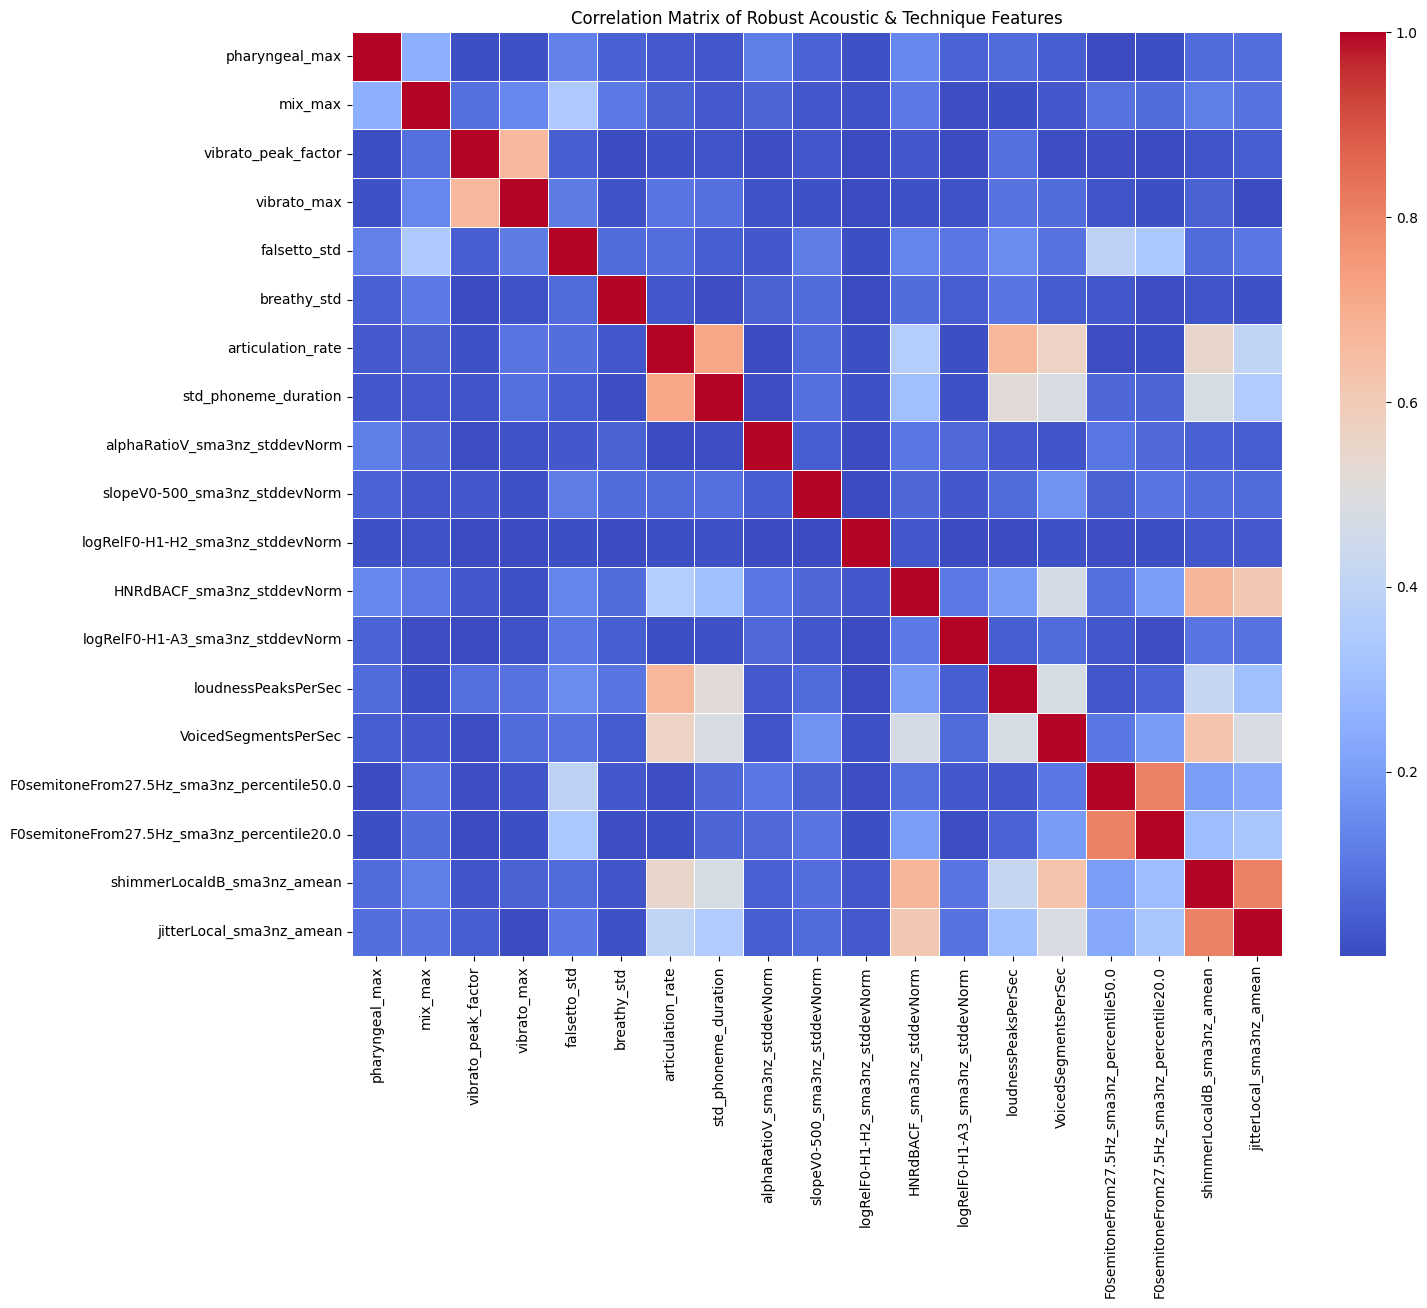

Pairs with high correlation (> 0.85):


In [ ]:
# Calculate the correlation matrix only for the robust features
corr_matrix = df_gtsinger[selected_feats].corr().abs()

# Heatmap
plt.figure(figsize=(15, 12))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Robust Acoustic & Technique Features')
plt.show()

# Locate pairs with high correlation (> 0.85)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.85)]

print("Pairs with high correlation (> 0.85):")
for col in to_drop:
    # Βρίσκουμε με ποιο άλλο feature έχει συσχέτιση
    correlated_with = upper.index[upper[col] > 0.85].tolist()
    print(f"'{col}' is highly correlated with: {correlated_with}")

In [ ]:
results_gtsinger = perform_loso_cross_validation(df_gtsinger, selected_feats, 'emotion', 'unique_singer_id', 'wav_path')

LOSO Cross-Validation for 7 singer...
Calculating Majority Vote per Performance Folder...

Fold 1 | Speaker: EN-Tenor-1 | Balanced Acc: 61.10% | F1: 0.61
Fold 2 | Speaker: DE-Soprano-1 | Balanced Acc: 67.48% | F1: 0.68
Fold 3 | Speaker: EN-Alto-2 | Balanced Acc: 64.01% | F1: 0.63
Fold 4 | Speaker: DE-Tenor-1 | Balanced Acc: 58.66% | F1: 0.59
Fold 5 | Speaker: FR-Tenor-1 | Balanced Acc: 57.63% | F1: 0.54
Fold 6 | Speaker: EN-Alto-1 | Balanced Acc: 59.72% | F1: 0.56
Fold 7 | Speaker: FR-Soprano-1 | Balanced Acc: 56.74% | F1: 0.51

FINAL LOSO RESULTS (Majority Vote)
Mean Balanced Accuracy (Per Speaker): 60.76%
Inter-Speaker Stability (STD): 3.53%
Mean F1-score: 0.59


## Feature Set Comparison

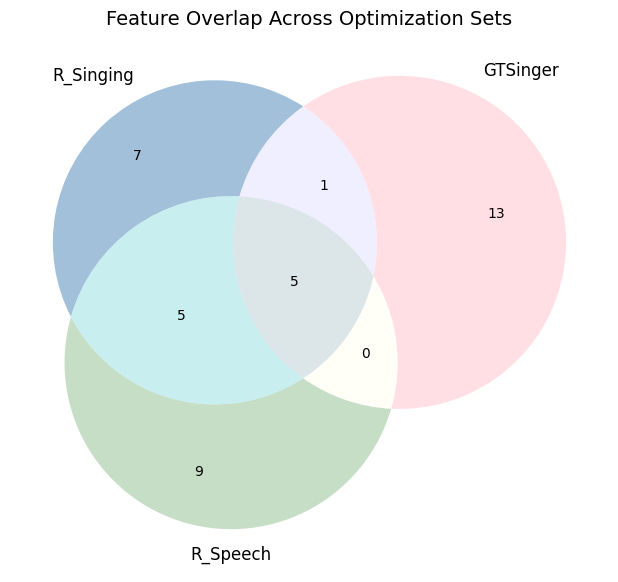

Common to ALL Sets (5)
• alphaRatioV_sma3nz_stddevNorm
• articulation_rate
• loudnessPeaksPerSec
• shimmerLocaldB_sma3nz_amean
• std_phoneme_duration

 Common to GTSinger-Optimized & Speech-Optimized (but not Singing-Optimized) (0)

 Common to GTSinger-Optimized & Singing-Optimized (but not Speech-Optimized) (1)
• pharyngeal_max

 Common to Singing & Speech-Optimized (but not GTSinger-Optimized) (5) ===
• F0semitoneFrom27.5Hz_sma3nz_percentile80.0
• F0semitoneFrom27.5Hz_sma3nz_stddevNorm
• F2amplitudeLogRelF0_sma3nz_stddevNorm
• HNRdBACF_sma3nz_amean
• alphaRatioV_sma3nz_amean


In [ ]:
singing_opt = set(expected_features_si)
gtsinger_opt = set(selected_feats)
speech_opt = set(expected_features_sp)
plt.figure(figsize=(10, 7))
# Create venn diagram for the three optimized sets
venn = venn3([singing_opt, gtsinger_opt, speech_opt],
             set_labels=('R_Singing', 'GTSinger', 'R_Speech'),
             set_colors=('steelblue', 'pink', 'darkseagreen'),
             alpha=0.5)

plt.title("Feature Overlap Across Optimization Sets", fontsize=14)
plt.show()

# Find common features between sets
intersection_all = sorted(list(singing_opt.intersection(gtsinger_opt, speech_opt)))
only_gtsinger = sorted(list(gtsinger_opt - singing_opt - speech_opt))

print(f"Common to ALL Sets ({len(intersection_all)})")
for feat in intersection_all:
    print(f"• {feat}")

common_gs = sorted(list(gtsinger_opt.intersection(speech_opt) - singing_opt))
print(f"\n Common to GTSinger-Optimized & Speech-Optimized (but not Singing-Optimized) ({len(common_gs)})")
for feat in common_gs:
    print(f"• {feat}")

common_gr = sorted(list(gtsinger_opt.intersection(singing_opt) - speech_opt))
print(f"\n Common to GTSinger-Optimized & Singing-Optimized (but not Speech-Optimized) ({len(common_gr)})")
for feat in common_gr:
    print(f"• {feat}")

common_rs = sorted(list(speech_opt.intersection(singing_opt) - gtsinger_opt))
print(f"\n Common to Singing & Speech-Optimized (but not GTSinger-Optimized) ({len(common_rs)}) ===")
for feat in common_rs:
    print(f"• {feat}")

In [ ]:
model_to_explain = RandomForestClassifier(
          n_estimators=200,
          max_depth=12,
          min_samples_leaf=10,
          class_weight='balanced',
          random_state=42
)

# fit to all GTSinger data
X = df_gtsinger[selected_feats]
y = df_gtsinger['emotion']
model_to_explain.fit(X, y)


RandomForestClassifier(class_weight='balanced', max_depth=12,
                       min_samples_leaf=10, n_estimators=200, random_state=42)

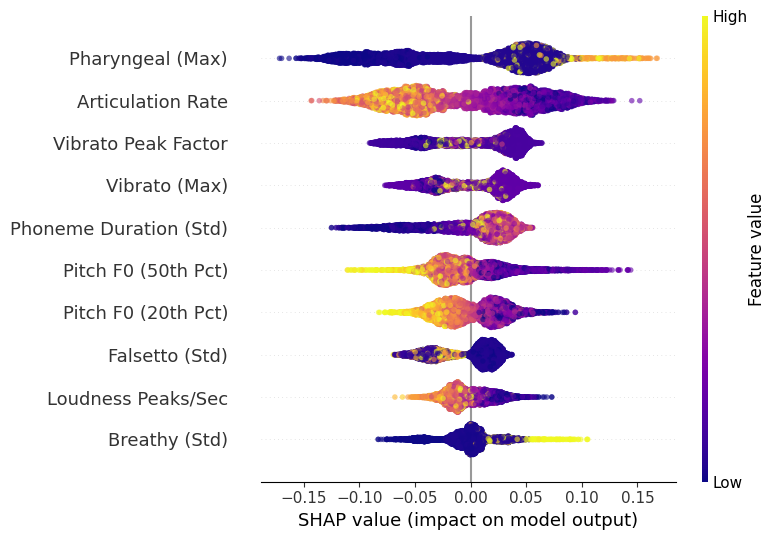

In [ ]:
# Feature mapping dictionary
feature_mapping = {
    "pharyngeal_max": "Pharyngeal (Max)",
    "articulation_rate": "Articulation Rate",
    "std_phoneme_duration": "Phoneme Duration (Std)",
    "vibrato_peak_factor": "Vibrato Peak Factor",
    "vibrato_max": "Vibrato (Max)",
    "falsetto_std": "Falsetto (Std)",
    "breathy_std": "Breathy (Std)",
    "loudnessPeaksPerSec": "Loudness Peaks/Sec",
    "F0semitoneFrom27.5Hz_sma3nz_percentile50.0": "Pitch F0 (50th Pct)",
    "F0semitoneFrom27.5Hz_sma3nz_percentile20.0": "Pitch F0 (20th Pct)"
}

# Rename columns in X
X_renamed = X.rename(columns=feature_mapping)

# Compute SHAP values
explainer = shap.TreeExplainer(model_to_explain)
shap_values = explainer.shap_values(X)
shap_to_plot = shap_values[:, :, 1]

plt.figure(figsize=(10, 6))

shap.summary_plot(
    shap_to_plot,
    X_renamed,
    plot_type="dot",
    alpha=0.6,
    max_display=10,  # Limits plot to top 10 features
    cmap="plasma",
    show=False
)

plt.tight_layout()
plt.show()

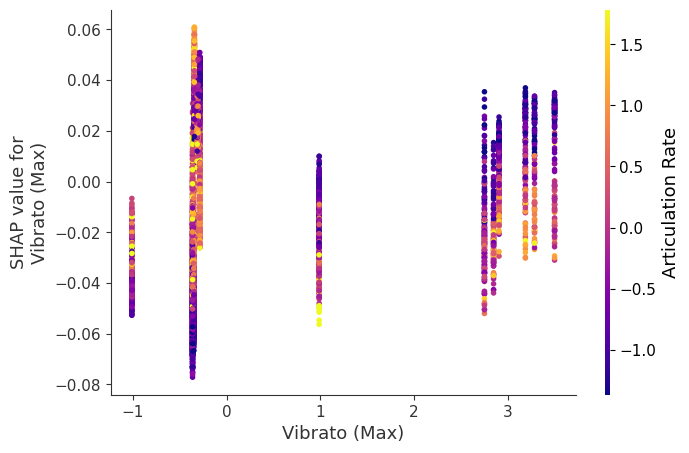

In [ ]:
# Dependence Plot for vibrato_std
# interaction_index='auto' will automatically find which feature vibrato_std
# is interacting with (has the strongest dependency)
shap.dependence_plot(
    "Vibrato (Max)",
    shap_values[:, :, 1],
    X_renamed,
    interaction_index='auto',
    cmap='plasma'
)